# Лабораторная работа: Машина опорных векторов (SVM)

<img src="svm_img.png" width=350>

Машина опорных векторов (Support Vector Machine, SVM) — один из классических алгоритмов машинного обучения. В этой лабораторной вы **построите SVM с нуля**: сведёте обучение модели к задаче квадратичного программирования, решите её готовым солвером, реализуете ядровой SVM и, наконец, примените свою реализацию к реальным медицинским данным (диагностика болезней сердца).

**Маршрут работы:**

1. **Линейное и квадратичное программирование** — разберём задачи линейного (LP) и квадратичного (QP) программирования, поймём, чем они отличаются, и научимся решать их библиотекой `cvxopt`.
2. **Линейный SVM** — разберём теорию и реализуем линейный SVM через QP-солвер.
3. **Двойственный переход и ядровой SVM** — перепишем задачу в двойственной форме и научимся строить нелинейные разделяющие поверхности с помощью ядер.
4. **Реальные данные** — возьмём датасет UCI о болезнях сердца, подготовим его средствами `pandas` и запустим на нём собственную реализацию SVM.

Результат лабораторной работы — **отчёт** в формате ноутбука IPython (ipynb-файл). Нам не интересен ваш код — важны рассуждения и эксперименты. Чем меньше кода, тем лучше всем: нам — меньше проверять, вам — проще найти ошибку или дополнить эксперимент.

Постарайтесь сделать ваш отчёт интересным рассказом, последовательно отвечающим на вопросы из заданий. Ответы на вопросы должны быть полными, чёткими и хорошо аргументированными.

## 0. Подготовка ноутбука

Подключим библиотеки, которые понадобятся на протяжении всей работы:

- [`NumPy`](https://numpy.org/) — операции с массивами и матрицами;
- [`Matplotlib`](https://matplotlib.org/) — графики;
- [`cvxopt`](https://cvxopt.org/) — солвер задач квадратичного программирования;
- [`scikit-learn`](https://scikit-learn.org/) — генерация выборок, разбиение данных, эталонные модели для сравнения;
- [`pandas`](https://pandas.pydata.org/) — работа с реальными табличными данными (часть 4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['font.size'] = 12

# фиксируем seed для воспроизводимости случайных экспериментов
np.random.seed(42)

In [2]:
# cvxopt не входит в стандартный набор Anaconda.
# Если библиотека не установлена — раскомментируйте следующую строку и выполните ячейку:
# !pip install cvxopt

In [3]:
from cvxopt import matrix, solvers

## 1. Линейное и квадратичное программирование

### 1.1. Линейное программирование: плоская цель

Начнём с самого простого типа задач оптимизации с ограничениями. В **линейном программировании** (LP) и целевая функция, и все ограничения линейны:

$$
\boldsymbol c^T \boldsymbol x \to \min_{\boldsymbol x}
\qquad
\text{при условиях: } \
\boldsymbol G\boldsymbol x \le \boldsymbol h, \qquad \boldsymbol A\boldsymbol x = \boldsymbol b
$$

Интуиция: целевая функция — не «чаша», а **наклонная плоскость**. Допустимая область, которую задают линейные ограничения, — выпуклый многоугольник (в многомерном случае — многогранник). Ключевой факт, который вы увидите на картинке ниже: **минимум линейной функции всегда достигается на границе — в вершине многоугольника** (либо вдоль целого ребра, если оно параллельно линиям уровня). «Внутрь» области оптимум не попадает никогда — плоской функции там двигаться некуда.

Откуда берутся такие задачи: LP — математика планирования: оптимальный план производства, рацион минимальной стоимости, транспортная задача. Слово «программирование» здесь означает «планирование», а не написание кода.

В cvxopt есть солвер и для LP: [`solvers.lp(c, G, h)`](https://cvxopt.org/examples/tutorial/linearprogramming.html) — интерфейс почти тот же, что у QP-солвера, только вместо матрицы $P$ передаётся вектор $\boldsymbol c$.

### 1.2. Пример: план кондитерской

Кондитерская печёт песочные ($x_1$ шт.) и бисквитные ($x_2$ шт.) пирожные. Прибыль — 30 и 40 рублей за штуку. Печь работает с загрузкой: песочное занимает 1 час, бисквитное — 2 часа, всего доступно 8 часов. Время кондитера: 3 часа на партию песочных, 2 часа — на бисквитные, всего 12 часов. Сколько печь, чтобы прибыль была максимальной?

$$
30x_1 + 40x_2 \to \max
\qquad
\text{при: } \
x_1 + 2x_2 \le 8, \quad 3x_1 + 2x_2 \le 12, \quad x_1 \ge 0, \ x_2 \ge 0
$$

Солвер умеет только **минимизировать**, поэтому максимизацию заменим минимизацией цели со знаком минус: $\boldsymbol c = (-30, -40)$:

In [4]:
c = matrix(np.array([-30.0, -40.0]), tc='d')

G = matrix(np.array([[ 1.0,  2.0],    #  x1 + 2x2 <= 8    (печь)
                     [ 3.0,  2.0],    #  3x1 + 2x2 <= 12  (кондитер)
                     [-1.0,  0.0],    # -x1        <= 0
                     [ 0.0, -1.0]]), tc='d')   # -x2 <= 0
h = matrix(np.array([8.0, 12.0, 0.0, 0.0]), tc='d')

sol_lp = solvers.lp(c, G, h)
print('x* =', np.array(sol_lp['x']).ravel())
print('прибыль =', -sol_lp['primal objective'])

# для самопроверки: должно получиться x* = (2, 3) и прибыль 180

     pcost       dcost       gap    pres   dres   k/t
 0: -1.6571e+02 -3.0000e+02  4e+01  0e+00  6e-01  1e+00
 1: -1.7911e+02 -1.8741e+02  2e+00  1e-16  4e-02  2e-01
 2: -1.7999e+02 -1.8008e+02  2e-02  3e-16  4e-04  2e-03
 3: -1.8000e+02 -1.8000e+02  2e-04  2e-16  4e-06  2e-05
 4: -1.8000e+02 -1.8000e+02  2e-06  4e-16  4e-08  2e-07
Optimal solution found.
x* = [1.99999992 3.00000004]
прибыль = 179.99999908647814


### 1.3. Визуализация: оптимум — в вершине

Нарисуем допустимую область (серым), линии уровня прибыли $30x_1 + 40x_2$ (синий пунктир) и отметим вершины многоугольника. Оптимум — та вершина, через которую линии уровня «проходят последними» при росте прибыли. Приём с булевыми массивами — тот же, что и в визуализации QP ниже:

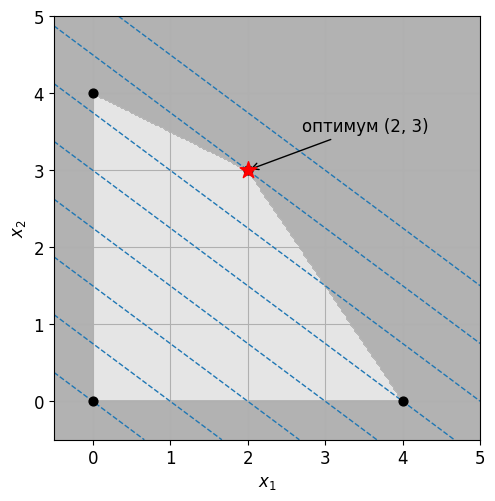

In [5]:
x1 = np.linspace(-0.5, 5.0, 200)
x2 = np.linspace(-0.5, 5.0, 200)
xx1, xx2 = np.meshgrid(x1, x2)

profit = 30*xx1 + 40*xx2
ok = (xx1 + 2*xx2 <= 8) & (3*xx1 + 2*xx2 <= 12) & (xx1 >= 0) & (xx2 >= 0)

vertices = np.array([[0, 0], [4, 0], [2, 3], [0, 4]], dtype=float)

plt.figure(figsize=(5.5, 5.5))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contourf(x1, x2, ok, 1, alpha=0.4, cmap='gray')
plt.contour(x1, x2, profit, levels=np.arange(0, 240, 30), colors='tab:blue',
            linestyles='--', linewidths=1)
plt.scatter(vertices[:, 0], vertices[:, 1], color='black', s=40, zorder=3)
plt.scatter([2], [3], color='red', s=160, marker='*', zorder=4)  # оптимум
plt.annotate('оптимум (2, 3)', (2, 3), xytext=(2.7, 3.5),
             arrowprops=dict(arrowstyle='->'))
plt.show()

### 1.4. Квадратичное программирование: чаша вместо плоскости

Теперь усложним цель. В **квадратичном программировании** (QP) минимизируется квадратичная функция — многомерная парабола — при тех же линейных ограничениях:

$$
\frac{1}{2}\boldsymbol x^T\boldsymbol P\boldsymbol x + \boldsymbol q^T\boldsymbol x \to \min_{\boldsymbol x}
\qquad
\text{при условиях: } \
\boldsymbol G\boldsymbol x \le \boldsymbol h, \qquad \boldsymbol A\boldsymbol x = \boldsymbol b
$$

Представьте чашу — график квадратичной функции: теперь у функции появилась собственная «низина», и ограничения лишь мешают в неё попасть. **Минимум может оказаться и внутри области** (если низина допустима), и на её границе — какой из случаев случится, заранее неизвестно. Если матрица $P$ положительно определена ($P \succ 0$), чаша строго выпуклая, и решение единственно.

Разберём обозначения:

| Объект | Размер | Смысл |
|---|---|---|
| $\boldsymbol x$ | $n$ | вектор переменных, которые мы подбираем |
| $\boldsymbol P$ | $n \times n$ | симметричная матрица, задающая «кривизну» чаши |
| $\boldsymbol q$ | $n$ | линейная часть, «наклоняющая» чашу |
| $\boldsymbol G\boldsymbol x \le \boldsymbol h$ | $m \times n$ | неравенства — «заборы»; каждое неравенство — отдельная строка |
| $\boldsymbol A\boldsymbol x = \boldsymbol b$ | $p \times n$ | равенства (в наших задачах их не будет) |

Сводим различия LP и QP в таблицу:

| | LP | QP |
|---|---|---|
| Целевая функция | линейная $\boldsymbol c^T\boldsymbol x$ — «наклонная плоскость» | квадратичная $\frac{1}{2}\boldsymbol x^T P\boldsymbol x + \boldsymbol q^T\boldsymbol x$ — «чаша» |
| Где может быть оптимум | только на границе: вершина или ребро | где угодно: внутри области или на границе |
| Единственность | не гарантирована (оптимум — целое ребро) | при $P \succ 0$ решение единственно |
| Солвер cvxopt | `solvers.lp(c, G, h)` | `solvers.qp(P, q, G, h)` |
| Типичные задачи | планы производства, рацион, транспорт | SVM, инвестиционный портфель, регрессия с ограничениями |

Почему SVM — это именно QP, станет ясно в разделе 2: ширина разделяющего коридора пропорциональна $1/\lVert\boldsymbol w\rVert$, и максимизировать её удобно квадратичным штрафом $\lVert\boldsymbol w\rVert^2$ при линейных ограничениях — линейной цели такой трик не под силу.

Задача QP хорошо изучена; помимо [CVXOPT](https://cvxopt.org/) (функция [`solvers.qp()`](https://cvxopt.org/examples/tutorial/qp.html)) существуют [Mosek](https://www.mosek.com/) (коммерческая, есть бесплатная академическая лицензия) и Matlab Optimization Toolbox (`quadprog`) — использовать можно любой.

### 1.5. Знакомство с `cvxopt`

Солверы `lp` и `qp` принимают ограничения в одинаковом виде, так что всё, что вы узнаете про матрицы ниже, работает в обоих случаях. Главный подводный камень: `cvxopt.matrix` заполняет данные **по столбцам**, а не по строкам, как привычный `NumPy`. Поэтому надёжнее всего создавать матрицы из готовых `numpy`-массивов — тогда сюрпризов не будет:

In [6]:
# Внимание: список из шести чисел превратился в матрицу 2x3,
# заполненную ПО СТОЛБЦАМ: первый столбец (1, 2), второй (3, 4), третий (5, 6)
A = matrix([1.0, 2.0, 3.0, 4.0, 5.0, 6.0], (2, 3))
print(A)
print('размер матрицы:', A.size)

# Проще передавать numpy-массивы с параметром tc='d' (числа двойной точности)
B = matrix(np.array([[1.0, 2.0, 3.0],
                     [4.0, 5.0, 6.0]]), tc='d')
print(B)

[ 1.00e+00  3.00e+00  5.00e+00]
[ 2.00e+00  4.00e+00  6.00e+00]

размер матрицы: (2, 3)
[ 1.00e+00  2.00e+00  3.00e+00]
[ 4.00e+00  5.00e+00  6.00e+00]



### 1.6. Первый запуск QP-солвера

Решим учебную задачу из [документации cvxopt](https://cvxopt.org/examples/tutorial/qp.html):

$$
\frac{1}{2}x_1^2 + 3x_1 + 4x_2 \to \min
\qquad
\text{при: } \
x_1 \ge 0, \ x_2 \ge 0, \ x_1 + 3x_2 \ge 15, \ 2x_1 + 5x_2 \le 100, \ 3x_1 + 4x_2 \le 80
$$

Квадратичная часть здесь задана матрицей $P = \begin{pmatrix} 1 & 0 \\ 0 & 0 \end{pmatrix}$, линейная — вектором $q = (3, 4)^T$. Дальше каждое неравенство нужно переписать в каноническом виде $g^T x \le h$, например: $x_1 \ge 0 \Leftrightarrow -x_1 \le 0$, а $x_1 + 3x_2 \ge 15 \Leftrightarrow -x_1 - 3x_2 \le -15$. Из получившихся строк-неравенств складываем матрицы $G$ и $h$:

In [7]:
P = matrix(np.diag([1.0, 0.0]), tc='d')
q = matrix(np.array([3.0, 4.0]), tc='d')

G = matrix(np.array([[-1.0,  0.0],    # -x1         <= 0     (это x1 >= 0)
                     [ 0.0, -1.0],    # -x2         <= 0     (это x2 >= 0)
                     [-1.0, -3.0],    # -x1 - 3x2   <= -15   (это x1 + 3x2 >= 15)
                     [ 2.0,  5.0],    #  2x1 + 5x2  <= 100
                     [ 3.0,  4.0]]), tc='d')   #  3x1 + 4x2 <= 80
h = matrix(np.array([0.0, 0.0, -15.0, 100.0, 80.0]), tc='d')

sol = solvers.qp(P, q, G, h)
print('x* =', np.array(sol['x']).ravel())
print('f(x*) =', sol['primal objective'])
# для самопроверки: должно получиться примерно x* = (0, 5) и f(x*) = 20

# чтобы солвер не печатал подробный лог при каждом вызове, выполните:
# solvers.options['show_progress'] = False

     pcost       dcost       gap    pres   dres
 0:  1.0780e+02 -7.6366e+02  9e+02  0e+00  4e+01
 1:  9.3245e+01  9.7637e+00  8e+01  1e-16  3e+00
 2:  6.7311e+01  3.2553e+01  3e+01  3e-18  1e+00
 3:  2.6071e+01  1.5068e+01  1e+01  9e-17  7e-01
 4:  3.7092e+01  2.3152e+01  1e+01  1e-16  4e-01
 5:  2.5352e+01  1.8652e+01  7e+00  3e-16  7e-17
 6:  2.0062e+01  1.9974e+01  9e-02  9e-17  7e-17
 7:  2.0001e+01  2.0000e+01  9e-04  6e-17  2e-16
 8:  2.0000e+01  2.0000e+01  9e-06  9e-17  4e-16
Optimal solution found.
x* = [7.13181641e-07 5.00000101e+00]
f(x*) = 20.00000617311241


### 1.7. Активные и неактивные ограничения

Ограничение-неравенство называется **активным** в точке оптимума $\boldsymbol x_\star$, если оно выполнено как точное равенство: $g^T \boldsymbol x_\star = h$. Образно: это тот «забор», которого минимум коснулся. Ограничение, до которого минимум «не дотянулся», — неактивное: его можно убрать, и решение не изменится.

Проверить активность легко: подставьте решение в ограничения и посмотрите, какие разности $h - g^T \boldsymbol x_\star$ равны нулю (с точностью до погрешности солвера, например $10^{-6}$):

In [8]:
G_np = np.array(G)
x_star = np.array(sol['x']).ravel()

for i, (g_row, h_i) in enumerate(zip(G_np, np.array(h).ravel())):
    slack = h_i - g_row @ x_star
    status = 'АКТИВНО' if abs(slack) < 1e-6 else 'неактивно'
    print(f'ограничение {i}:  h - g^T x* = {slack:8.4f}  ->  {status}')

ограничение 0:  h - g^T x* =   0.0000  ->  АКТИВНО
ограничение 1:  h - g^T x* =   5.0000  ->  неактивно
ограничение 2:  h - g^T x* =   0.0000  ->  неактивно
ограничение 3:  h - g^T x* =  75.0000  ->  неактивно
ограничение 4:  h - g^T x* =  60.0000  ->  неактивно


### 1.8. Визуализация QP-задачи (пригодится в задании 1)

Нарисуем для двумерной QP-задачи линии уровня функции и серым цветом — область, в которой ограничения **выполнены**. Обратите внимание на приём: сравнение массива с числом (`xx1 + xx2 <= 5`) даёт **булев массив** той же формы, а булевы массивы комбинируются операторами `&` и `|` — так мы «раскрашиваем» допустимую область:

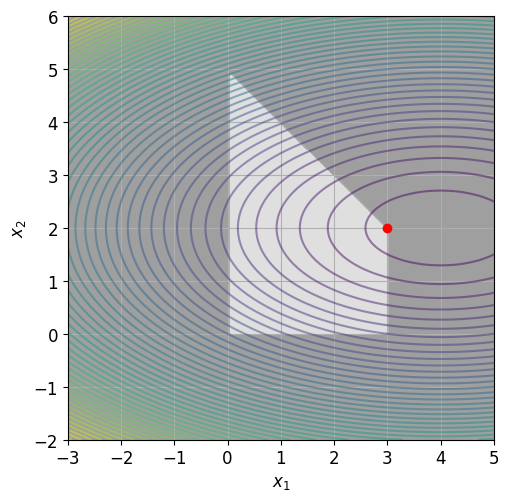

In [9]:
x1 = np.linspace(-3, 5, 100)
x2 = np.linspace(-2, 6, 100)
xx1, xx2 = np.meshgrid(x1, x2)

f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2                      # оптимизируемая функция
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)  # допустимая область

plt.figure(figsize=(5.5, 5.5))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contour(x1, x2, f, 50, alpha=0.5)
plt.contourf(x1, x2, ok, 1, alpha=0.5, cmap='gray')
plt.scatter([3], [2], color='red', zorder=3)  # точка (3, 2): проверьте, что солвер найдёт её же
plt.show()

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 1. Линейное и квадратичное программирование</h2>

**Часть A. Линейное программирование**

1. Мебельная мастерская выпускает столы ($x_1$) и стулья ($x_2$). Прибыль: 3 и 2 тыс. руб. за изделие. Цех сборки тратит на стол 2 часа, на стул — 1 час, всего доступно 6 часов; отделка — по 1 часу на любое изделие, всего 4 часа. Составьте задачу LP, переведите максимизацию прибыли в минимизацию и решите её с помощью `solvers.lp`.
2. Нарисуйте допустимую область, линии уровня прибыли и решение (по образцу п. 1.3). Проверьте ответ, перебрав все вершины многоугольника: каждую вершину найдите как решение системы двух линейных уравнений и подставьте в прибыль.
3. Подберите другие коэффициенты прибыли, при которых оптимальным станет **целое ребро** многоугольника, а не одна вершина. Что вернёт солвер в этом случае?

**Часть B. Квадратичное программирование**

4. Решите с помощью `solvers.qp` задачу
$$f(\boldsymbol x) = -8x_1 - 16x_2 + x_1^2 + 4x_2^2 \to \min, \qquad
x_1 + x_2 \le 5, \quad 0 \le x_1 \le 3, \quad x_2 \ge 0.$$
   Сначала найдите минимум **без ограничений** (приравняв градиент к нулю) и убедитесь, что он нарушает ограничения. Затем решите задачу с ограничениями и отметьте решение на картинке из п. 1.8.
5. Какие из ограничений **активны**, а какие можно выбросить без изменения решения? Проверьте экспериментально: решите задачу, удалив «лишнее» ограничение, и сравните ответы.
6. Сравните части A и B: в какой задаче оптимум обязан лежать на границе, а в какой может оказаться внутри области? Как это связано с видом целевой функции («плоскость» против «чаши»)?

## ✍️ Решение задания 1

### Часть A. Линейное программирование: мебельная мастерская

Переменные: $x_1$ — число столов, $x_2$ — число стульев. Задача:

$$
3x_1 + 2x_2 \to \max
\qquad
\text{при: } \
2x_1 + x_2 \le 6 \ (\text{сборка}), \quad x_1 + x_2 \le 4 \ (\text{отделка}), \quad x_1 \ge 0, \ x_2 \ge 0.
$$

Солвер умеет только минимизировать, поэтому решаем эквивалентную задачу $-3x_1 - 2x_2 \to \min$, т.е. $\boldsymbol c = (-3, -2)$.

Отключим подробный лог солвера и сразу ужесточим критерии остановки. cvxopt — метод **внутренней точки**: он подходит к оптимуму изнутри допустимой области, и ответ точен лишь до допуска сходимости (по умолчанию $\sim 10^{-7}$). Это важно ниже — при проверке активности ограничений и поиске опорных векторов «на глаз» по невязке.

In [10]:
solvers.options['show_progress'] = False
solvers.options['abstol'] = 1e-10
solvers.options['reltol'] = 1e-10
solvers.options['feastol'] = 1e-10
solvers.options['maxiters'] = 200

c = matrix(np.array([-3.0, -2.0]))
G_lp = matrix(np.array([[ 2.0,  1.0],    # 2x1 + x2 <= 6   (сборка)
                        [ 1.0,  1.0],    #  x1 + x2 <= 4   (отделка)
                        [-1.0,  0.0],    # -x1      <= 0
                        [ 0.0, -1.0]]))  # -x2      <= 0
h_lp = matrix(np.array([6.0, 4.0, 0.0, 0.0]))

sol_furn = solvers.lp(c, G_lp, h_lp)
x_furn = np.array(sol_furn['x']).ravel()
print('x* =', x_furn.round(4), '| прибыль =', round(-sol_furn['primal objective'], 4), 'тыс. руб.')

x* = [2. 2.] | прибыль = 10.0 тыс. руб.


**Проверка перебором вершин.** Каждая вершина многоугольника — пересечение двух прямых-границ. Переберём все пары ограничений, решим систему $2\times 2$ и оставим только допустимые точки:

In [11]:
from itertools import combinations

def lp_vertices(G, h):
    # все вершины многоугольника {x : Gx <= h} в R^2
    G, h = np.array(G), np.array(h).ravel()
    verts = []
    for i, j in combinations(range(len(h)), 2):
        M = G[[i, j]]
        if abs(np.linalg.det(M)) < 1e-12:      # параллельные прямые
            continue
        v = np.linalg.solve(M, h[[i, j]])
        if np.all(G @ v <= h + 1e-9):          # точка допустима
            verts.append(v)
    return np.unique(np.round(verts, 9), axis=0)

verts = lp_vertices(G_lp, h_lp)
for v in verts:
    print(f'вершина ({v[0]:.0f}, {v[1]:.0f}):  прибыль = {3*v[0] + 2*v[1]:.0f}')

вершина (-0, -0):  прибыль = -0
вершина (0, 4):  прибыль = 8
вершина (2, 2):  прибыль = 10
вершина (3, -0):  прибыль = 9


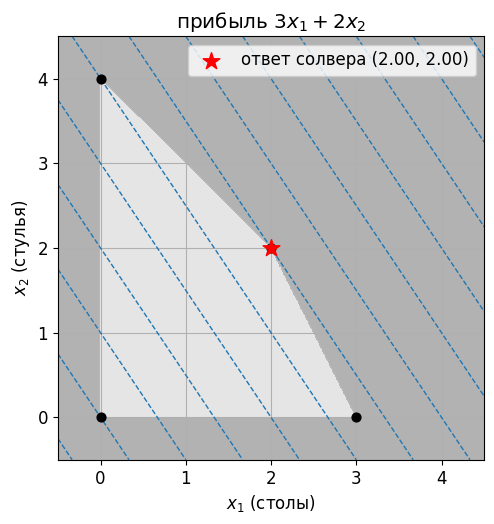

In [12]:
def plot_lp(profit_coef, G, h, x_opt, title, edge=None):
    x1 = np.linspace(-0.5, 4.5, 300)
    x2 = np.linspace(-0.5, 4.5, 300)
    xx1, xx2 = np.meshgrid(x1, x2)
    Gn, hn = np.array(G), np.array(h).ravel()
    ok = np.all(Gn[:, 0, None, None] * xx1 + Gn[:, 1, None, None] * xx2 <= hn[:, None, None], axis=0)
    profit = profit_coef[0] * xx1 + profit_coef[1] * xx2
    V = lp_vertices(G, h)

    plt.figure(figsize=(5.5, 5.5))
    plt.grid(True)
    plt.xlabel('$x_1$ (столы)'); plt.ylabel('$x_2$ (стулья)')
    plt.contourf(x1, x2, ok, 1, alpha=0.4, cmap='gray')
    plt.contour(x1, x2, profit, levels=15, colors='tab:blue', linestyles='--', linewidths=1)
    plt.scatter(V[:, 0], V[:, 1], color='black', s=40, zorder=3)
    if edge is not None:
        plt.plot(edge[:, 0], edge[:, 1], color='tab:green', lw=5, alpha=0.7, label='оптимальное ребро')
    plt.scatter(*x_opt, color='red', s=160, marker='*', zorder=4, label=f'ответ солвера ({x_opt[0]:.2f}, {x_opt[1]:.2f})')
    plt.title(title); plt.legend(loc='upper right')
    plt.show()

plot_lp((3, 2), G_lp, h_lp, x_furn, 'прибыль $3x_1 + 2x_2$')

**Оптимальное ребро.** Оптимум «растекается» по ребру, когда линии уровня прибыли параллельны одной из сторон многоугольника. Возьмём прибыль $x_1 + x_2$ (1 и 1 тыс. руб.) — она параллельна ограничению отделки $x_1 + x_2 \le 4$, и все точки ребра от $(2, 2)$ до $(0, 4)$ дают одну и ту же прибыль 4. Аналогично прибыль $2x_1 + x_2$ параллельна ограничению сборки (ребро от $(3,0)$ до $(2,2)$).

прибыль 1x1 + 1x2:  солвер вернул x* = [1.5487 2.4513],  прибыль = 4.0000


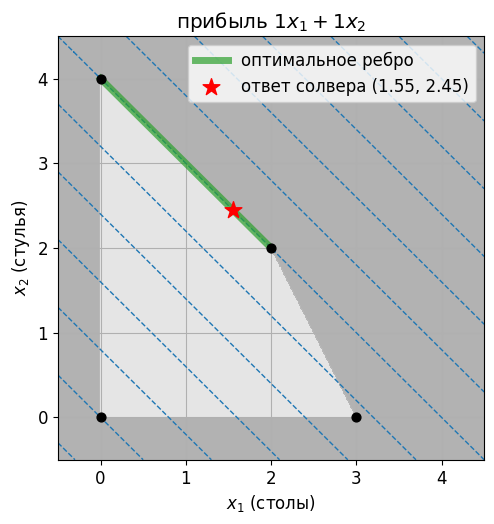

прибыль 2x1 + 1x2:  солвер вернул x* = [2.4591 1.0818],  прибыль = 6.0000


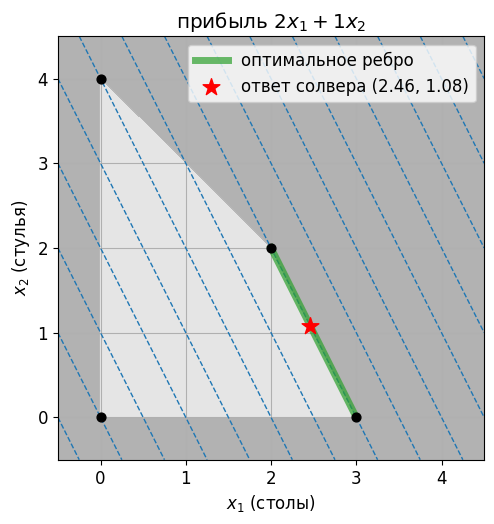

In [13]:
for coef, edge in [((1.0, 1.0), np.array([[2, 2], [0, 4]])),
                   ((2.0, 1.0), np.array([[3, 0], [2, 2]]))]:
    s = solvers.lp(matrix(-np.array(coef)), G_lp, h_lp)
    xe = np.array(s['x']).ravel()
    print(f'прибыль {coef[0]:.0f}x1 + {coef[1]:.0f}x2:  солвер вернул x* = {xe.round(4)},  прибыль = {-s["primal objective"]:.4f}')
    plot_lp(coef, G_lp, h_lp, xe, f'прибыль ${coef[0]:.0f}x_1 + {coef[1]:.0f}x_2$', edge=edge)

### Часть B. Квадратичное программирование

**Безусловный минимум.** $\nabla f = (2x_1 - 8, \; 8x_2 - 16) = 0 \Rightarrow \boldsymbol x^{\text{unc}} = (4, 2)$, $f(\boldsymbol x^{\text{unc}}) = -32$. Проверим ограничения:

In [14]:
f_qp = lambda x: -8*x[0] - 16*x[1] + x[0]**2 + 4*x[1]**2
x_unc = np.array([4.0, 2.0])
print('f(x_unc) =', f_qp(x_unc))
print('x1 + x2 <= 5 :', x_unc.sum() <= 5, f'({x_unc.sum()})')
print('0 <= x1 <= 3 :', 0 <= x_unc[0] <= 3)
print('x2 >= 0      :', x_unc[1] >= 0)

f(x_unc) = -32.0
x1 + x2 <= 5 : False (6.0)
0 <= x1 <= 3 : False
x2 >= 0      : True


Безусловный минимум нарушает **два** ограничения: $x_1 \le 3$ и $x_1 + x_2 \le 5$. Значит, условный минимум лежит на границе.

Приводим к стандартному виду: $f = \frac{1}{2}\boldsymbol x^T P \boldsymbol x + \boldsymbol q^T\boldsymbol x$ с $P = \operatorname{diag}(2, 8)$ (не $\operatorname{diag}(1, 4)$ — из-за множителя $\frac12$!), $\boldsymbol q = (-8, -16)$.

In [15]:
P_qp = matrix(np.diag([2.0, 8.0]))
q_qp = matrix(np.array([-8.0, -16.0]))
G_qp_np = np.array([[ 1.0,  1.0],    # x1 + x2 <= 5
                    [-1.0,  0.0],    # x1 >= 0
                    [ 1.0,  0.0],    # x1 <= 3
                    [ 0.0, -1.0]])   # x2 >= 0
h_qp_np = np.array([5.0, 0.0, 3.0, 0.0])
names_qp = ['x1 + x2 <= 5', 'x1 >= 0', 'x1 <= 3', 'x2 >= 0']

sol_qp = solvers.qp(P_qp, q_qp, matrix(G_qp_np), matrix(h_qp_np))
x_qp = np.array(sol_qp['x']).ravel()
print('x* =', x_qp.round(5), '| f(x*) =', round(sol_qp['primal objective'], 5))

x* = [3.      1.99999] | f(x*) = -31.0


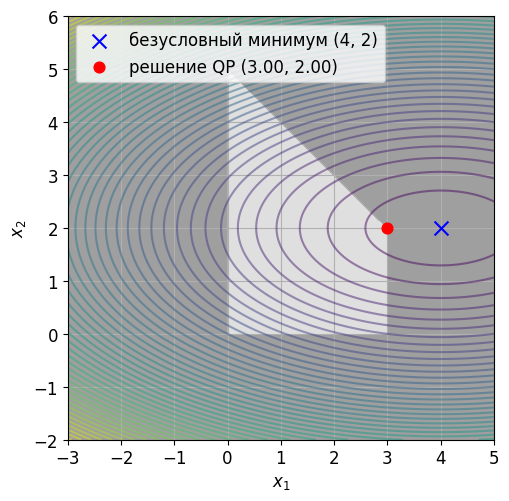

In [16]:
x1 = np.linspace(-3, 5, 200)
x2 = np.linspace(-2, 6, 200)
xx1, xx2 = np.meshgrid(x1, x2)
f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)

plt.figure(figsize=(5.5, 5.5))
plt.grid(True)
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.contour(x1, x2, f, 50, alpha=0.5)
plt.contourf(x1, x2, ok, 1, alpha=0.5, cmap='gray')
plt.scatter(*x_unc, color='blue', marker='x', s=100, zorder=3, label='безусловный минимум (4, 2)')
plt.scatter(*x_qp, color='red', zorder=3, s=60, label=f'решение QP ({x_qp[0]:.2f}, {x_qp[1]:.2f})')
plt.legend(loc='upper left')
plt.show()

**Активные ограничения.** Посмотрим на невязки $h - g^T\boldsymbol x_\star$ и на множители Лагранжа (двойственные переменные), которые cvxopt возвращает в `sol['z']`. Затем — эксперимент: по очереди выбросим каждое ограничение и перерешаем задачу.

In [17]:
lam = np.array(sol_qp['z']).ravel()
for name, g, hi, l in zip(names_qp, G_qp_np, h_qp_np, lam):
    slack = hi - g @ x_qp
    print(f'{name:14s} невязка = {slack:8.5f}  множитель = {l:8.5f}  ->  {"АКТИВНО" if abs(slack) < 1e-4 else "неактивно"}')

print()
for k, name in enumerate(names_qp):
    keep = [i for i in range(4) if i != k]
    s = solvers.qp(P_qp, q_qp, matrix(G_qp_np[keep]), matrix(h_qp_np[keep]))
    xs = np.array(s['x']).ravel()
    print(f'без "{name:12s}":  x* = {xs.round(4)},  f = {s["primal objective"]:.4f}')

x1 + x2 <= 5   невязка =  0.00001  множитель =  0.00008  ->  АКТИВНО
x1 >= 0        невязка =  3.00000  множитель =  0.00000  ->  неактивно
x1 <= 3        невязка =  0.00000  множитель =  1.99992  ->  АКТИВНО
x2 >= 0        невязка =  1.99999  множитель =  0.00000  ->  неактивно

без "x1 + x2 <= 5":  x* = [3. 2.],  f = -31.0000
без "x1 >= 0     ":  x* = [3. 2.],  f = -31.0000
без "x1 <= 3     ":  x* = [3.2 1.8],  f = -31.2000
без "x2 >= 0     ":  x* = [3. 2.],  f = -31.0000


### Выводы по заданию 1

**Часть A.**

1. Оптимальный план — **2 стола и 2 стула**, прибыль **10 тыс. руб.** Перебор вершин подтверждает ответ: $(0,0) \to 0$, $(3,0) \to 9$, $(0,4) \to 8$, $(2,2) \to 10$. В оптимуме оба «ресурсных» ограничения выполнены как равенства: $2\cdot2 + 2 = 6$ часов сборки и $2 + 2 = 4$ часа отделки. Мастерская загружена полностью.
2. Когда линии уровня прибыли параллельны стороне многоугольника (прибыль $x_1 + x_2$ или $2x_1 + x_2$), оптимальна **любая точка ребра**: решение не единственно. Солвер при этом вернул **не вершину, а точку внутри ребра**: $(1.55, 2.45)$ и $(2.46, 1.08)$. Причина в том, что cvxopt — метод внутренней точки: он движется к оптимальному множеству изнутри области и сходится к его «центру». Симплекс-метод на этой же задаче вернул бы вершину. Прибыль в обоих случаях правильная (4 и 6).

**Часть B.**

4. Безусловный минимум $(4, 2)$, $f = -32$, нарушает ограничения $x_1 \le 3$ и $x_1 + x_2 \le 5$. Решение с ограничениями — $\boldsymbol x_\star = (3, 2)$, $f(\boldsymbol x_\star) = -31$: оно лежит на границе (красная точка на картинке, совпадает с отмеченной в п. 1.8).
5. Ограничения:
   - $x_1 \le 3$ — **активно**, множитель Лагранжа $\lambda \approx 2$. Это единственное ограничение, которое реально «держит» решение: без него минимум уезжает в $(3.2, 1.8)$, $f = -31.2$;
   - $x_1 + x_2 \le 5$ — интересный **вырожденный** случай. В точке $(3, 2)$ оно выполнено как точное равенство ($3 + 2 = 5$), то есть формально активно, но его множитель равен $0$. Забор касается решения, но не давит на него: при $x_1 = 3$ функция и так минимальна по $x_2$ ровно в $x_2 = 2$, потому что $\partial f/\partial x_2 = 8x_2 - 16 = 0$. Условие ККТ $-\nabla f(\boldsymbol x_\star) = (2, 0) = \lambda_{x_1 \le 3}(1, 0) + \lambda_{x_1+x_2 \le 5}(1, 1)$ даёт $\lambda_{x_1+x_2\le5} = 0$. Поэтому его **можно выбросить**, и решение не изменится, что видно в эксперименте. Из-за вырожденности метод внутренней точки подходит к этой границе медленно: невязка $\sim 10^{-5}$ даже при допуске солвера $10^{-10}$. Поэтому активность здесь проверяем с допуском $10^{-4}$;
   - $x_1 \ge 0$, $x_2 \ge 0$ — неактивны (невязки 3 и 2), их удаление ничего не меняет.
6. **LP против QP.** В LP градиент цели постоянен и ненулевой ($\boldsymbol c$). Из любой внутренней точки можно сдвинуться против $\boldsymbol c$ и улучшить цель, поэтому оптимум **обязан** лежать на границе: в вершине или на целом ребре. У «чаши» QP есть собственный минимум. Если он допустим, ответом будет внутренняя точка: например, при ограничениях $x_1 \le 5$, $x_1 + x_2 \le 7$ ответ был бы $(4, 2)$. Если нет, как в нашей задаче, ответ окажется на границе, но не обязательно в вершине: $(3, 2)$ лежит на стороне $x_1 = 3$, а ограничение $x_1 + x_2 \le 5$ задевает её лишь случайно. Кроме того, при $P \succ 0$ решение QP единственно, а у LP может быть целое ребро решений (п. 3).

## 2. Линейный SVM

### 2.1. Разделяющая гиперплоскость и зазор

Постановка задачи: есть обучающая выборка $\{(\boldsymbol x_n, y_n)\}_{n=1}^N$, где $\boldsymbol x_n \in \mathbb{R}^d$ — вектор признаков объекта, а метка класса $y_n \in \{+1, -1\}$. Нужно по выборке построить правило, отличающее классы.

SVM ищет разделяющую гиперплоскость

$$f(\boldsymbol x) = \boldsymbol w^T \boldsymbol x + b, \qquad \hat{y}(\boldsymbol x) = \operatorname{sign} f(\boldsymbol x),$$

где $\boldsymbol w \in \mathbb{R}^d$ — вектор весов, $b$ — сдвиг. Интуиция метода: между классами есть «коридор» (**зазор**, margin), и чем он шире, тем увереннее классификатор ведёт себя на новых данных. Границы коридора — это линии уровня $f(\boldsymbol x) = +1$ и $f(\boldsymbol x) = -1$, а его ширина равна $\dfrac{2}{\lVert\boldsymbol w\rVert}$. Поэтому «сделать зазор максимальным» — то же самое, что «сделать $\lVert\boldsymbol w\rVert$ минимальным».

### 2.2. Если выборку нельзя разделить идеально: переменные $\xi_n$

В идеальном мире классы разделяются прямой, и все объекты лежат вне коридора, каждый на своей стороне. На практике объекты «залезают» в коридор или на чужую сторону. Поэтому каждому объекту разрешается **нарушать правила** — за плату. Вводится переменная ослабления (slack variable) $\xi_n \ge 0$ — величина нарушения, измеренная в долях полуширины коридора:

- $\xi_n = 0$ — объект лежит «по правилам»: строго вне коридора, на своей стороне;
- $0 < \xi_n < 1$ — объект внутри коридора, но всё ещё на своей стороне границы;
- $\xi_n > 1$ — объект ошибается: лежит на чужой стороне.

Обучение SVM — это оптимизационная задача по переменным $\boldsymbol w$, $b$, $\boldsymbol \xi$:

$$
\begin{gathered}
\frac{1}{2} \lVert\boldsymbol w\rVert^2 + C \sum_{n=1}^N \xi_n \to \min \\
\text{при: } \quad y_n (\boldsymbol w^T \boldsymbol x_n + b) \ge 1 - \xi_n, \qquad \xi_n \ge 0, \qquad n = 1, \dots, N
\end{gathered}
$$

Первое слагаемое штрафует узкий коридор (минимизируем $\lVert\boldsymbol w\rVert$ = максимизируем зазор), второе — суммарное нарушение границ. Гиперпараметр $C$ — «цена» единицы нарушения:

- **большое $C$** → нарушения «дорогие» → модель стремится не ошибаться на обучении даже ценой узкого коридора; растёт риск переобучения;
- **маленькое $C$** → коридор шире, часть объектов ошибается; при слишком малом $C$ модель недообучается.

$C$ фиксируется **до** обучения и не оптимизируется вместе с параметрами модели. Подбирают его на отложенной выборке или кросс-валидации; поскольку порядок оптимального $C$ заранее неизвестен, значения перебирают по логарифмической сетке: $10^{-3}, 10^{-2}, \dots, 10^{5}$.

### 2.3. Опорные векторы

После решения задачи $(\boldsymbol w_\star, b_\star, \boldsymbol \xi_\star)$ часть ограничений становится **активной** — обращается в точное равенство:

$$y_n (\boldsymbol w_\star^T \boldsymbol x_n + b_\star) = 1 - \xi_{\star,n}.$$

Объекты с активными ограничениями называются **опорными векторами**: это объекты, которые «держат» коридор — уберите все остальные, и решение не изменится. На практике активность проверяют с небольшим допуском, например $\lvert\, y_n f(\boldsymbol x_n) - (1 - \xi_n) \,\rvert < 10^{-5}$.

### 2.4. Сведение к задаче QP

Задача из п. 2.2 — это QP-задача, просто переменные «спрятаны» в одном длинном векторе $\boldsymbol z = (\boldsymbol w, \, b, \, \boldsymbol \xi)$ длины $d + 1 + N$. Осталось записать её в стандартной форме из п. 1.4. Сопоставьте (и проверяйте себя размерами!):

| Элемент задачи | Что получится |
|:---:|:---:|
| Квадратичная часть $\frac{1}{2}\boldsymbol z^T P \boldsymbol z = \frac{1}{2}\lVert\boldsymbol w\rVert^2$ | $P = \operatorname{diag}(\underbrace{1, \dots, 1}_{d}, \underbrace{0, \dots, 0}_{1+N})$ — единицы только для компонент $\boldsymbol w$ |
| Линейная часть $\boldsymbol q^T \boldsymbol z = C \sum_n \xi_n$ | $q = (\underbrace{0, \dots, 0}_{d+1}, \underbrace{C, \dots, C}_{N})$ |
| Правильная классификация: $y_n(\boldsymbol w^T \boldsymbol x_n + b) \ge 1 - \xi_n$, то есть $-y_n(\boldsymbol w^T \boldsymbol x_n + b) - \xi_n \le -1$ | $N$ строк матрицы $G$: $(-y_n \boldsymbol x_n^T, \; -y_n, \; -\boldsymbol e_n^T)$; соответствующие элементы $h_n = -1$ |
| Неотрицательность: $\xi_n \ge 0$, то есть $-\xi_n \le 0$ | ещё $N$ строк $G$: $(\boldsymbol 0, \; 0, \; -\boldsymbol e_n^T)$; элементы $h_n = 0$ |

Здесь $\boldsymbol e_n$ — строка из нулей с единицей на позиции $n$. Итого $G$ имеет размер $2N \times (d + 1 + N)$. Собирать такие матрицы удобно блоками: `np.hstack` / `np.vstack`, либо создать нулевую матрицу нужного размера и заполнить срезы.

**Проверка на крошечном примере ($N = 2$ объекта, $d = 2$ признака):** строка $G$ для первого объекта будет равна $(-y_1 x_{11}, \; -y_1 x_{12}, \; -y_1, \; -1, \; 0)$ — два признака, затем $b$, затем $\xi_1, \xi_2$.

### 2.5. Явное преобразование признаков

Линейная граница — грубая модель: часто классы разделимы, но не прямой. Приём: добавить к признакам их нелинейные функции, например все попарные произведения

$$\phi(x_1, x_2) = (x_1, \; x_2, \; x_1^2, \; x_1 x_2, \; x_2^2),$$

и обучить **линейный** SVM уже в новом признаковом пространстве $\boldsymbol x \mapsto \phi(\boldsymbol x)$. В исходном пространстве граница окажется кривой: уравнение $\boldsymbol w^T \phi(\boldsymbol x) + b = 0$ — квадратное уравнение относительно $x_1, x_2$, и его решением может быть, например, эллипс.

Посмотрите на анимацию: слева два «кольца» классов, которые невозможно разделить прямой; справа — те же точки после добавления всего одной нелинейной функции $z = x_1^2 + x_2^2$. В трёхмерном пространстве классы разделяются обычной плоскостью, а её «проекция» обратно на плоскость — окружность:

<img src="kernel_trick.gif" width="720">

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 2. Линейный SVM</h2>

1. Сведите задачу обучения линейного SVM к QP (п. 2.4) и реализуйте обучение в классе `LinearSVM` (скелет ниже) при помощи QP-солвера. **Не забудьте:** солверу нужны метки $y_n \in \{+1, -1\}$; если метки закодированы нулями и единицами, преобразуйте их: `y = 2 * y - 1`.
2. Сгенерируйте три случайные двумерные выборки для бинарной классификации:
   - с линейно разделимыми классами;
   - с хорошо разделимыми классами, но **не линейно**;
   - с плохо разделимыми классами по имеющимся признакам.
3. Протестируйте линейный SVM на этих выборках. Покажите на плоскости разделяющую прямую и границы коридора $f(\boldsymbol x) = \pm 1$. Выделите опорные векторы точками другой формы или большего размера. Постройте классификаторы с разными значениями параметра $C$.
4. Как зависит число опорных векторов от параметра $C$ для каждой из выборок? Объясните, почему.
5. Используя явное преобразование признаков (п. 2.5), обучите методом опорных векторов квадратичную разделяющую поверхность и покажите её на плоскости.

### Подсказка: генерация выборок

В `scikit-learn` есть удобные генераторы:

- [`make_blobs`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html) — два «облака» точек: линейно разделимый случай;
- [`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) — две «полумесяца»: классы разделимы, но не линейно;
- [`make_classification`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html) — гибкая настройка; параметр `flip_y` «переворачивает» долю меток и делает классы плохо разделимыми.

Всегда фиксируйте `random_state`, чтобы выборка не менялась при перезапуске ноутбука:

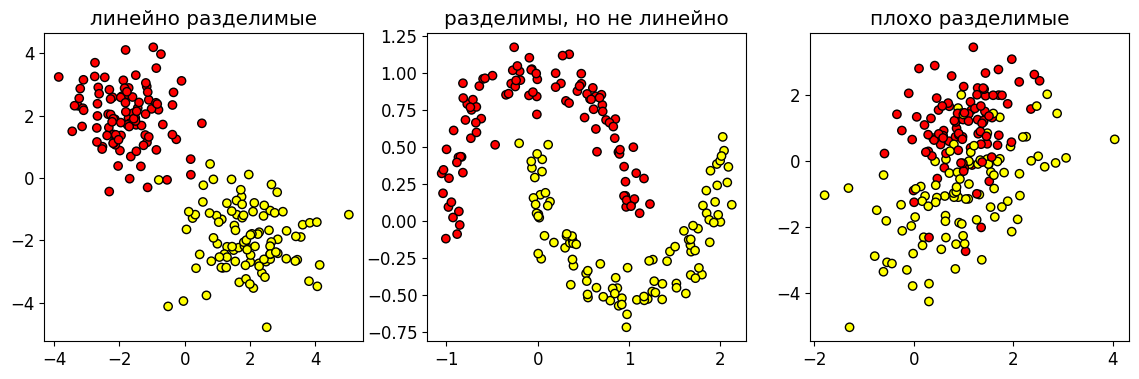

In [18]:
from sklearn.datasets import make_blobs, make_moons, make_classification

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

X1, y1 = make_blobs(n_samples=200, centers=[(-2, 2), (2, -2)], random_state=1)
X2, y2 = make_moons(n_samples=200, noise=0.1, random_state=1)
X3, y3 = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, flip_y=0.15, random_state=1)

for ax, X, y, title in zip(axes, [X1, X2, X3], [y1, y2, y3],
                           ['линейно разделимые', 'разделимы, но не линейно', 'плохо разделимые']):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black')
    ax.set_title(title)

plt.show()

### Подсказка: визуализация решающего правила

Стандартный приём: покрыть плоскость сеткой точек, применить к каждой модель и нарисовать результат фоном (`contourf`), а линию уровня $f(\boldsymbol x) = 0$ и границы коридора $f(\boldsymbol x) = \pm 1$ — линиями (`contour`). Ниже готовая функция; она ожидает от модели метод `decision_function(X)`, возвращающий числа $f(\boldsymbol x)$:

In [19]:
def plot_decision_boundary(model, X, y, support_vectors=None, figsize=(6, 6)):
    # рисует точки выборки, разделяющую поверхность f(x) = 0 (сплошная линия)
    # и границы коридора f(x) = ±1 (пунктир)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=figsize)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2)
    plt.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    if support_vectors is not None and len(support_vectors) > 0:
        plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=220,
                    facecolors='none', edgecolors='black', linewidths=1.5, zorder=3)
    plt.tight_layout()

### Скелет класса `LinearSVM`

Чтобы ваша модель «дружила» с инструментами `scikit-learn` (`cross_val_score`, `GridSearchCV`, пайплайны и т.д.), достаточно наследоваться от [`BaseEstimator`](https://scikit-learn.org/stable/developers/develop.html) и реализовать методы `fit` и `predict`:

In [20]:
from sklearn.base import BaseEstimator

class LinearSVM(BaseEstimator):
    def __init__(self, C=1.0, transform=None):
        self.C = C                  # цена нарушения границы
        self.transform = transform  # необязательное преобразование признаков phi(x)

    def fit(self, X, y):
        X_orig = np.asarray(X, dtype=float)
        X = self.transform(X_orig) if self.transform is not None else X_orig
        y = np.asarray(y, dtype=float)
        N, d = X.shape

        # переменные z = (w, b, xi), длина d + 1 + N
        P = np.zeros((d + 1 + N, d + 1 + N))
        P[:d, :d] = np.eye(d)                           # 1/2 ||w||^2
        q = np.r_[np.zeros(d + 1), self.C * np.ones(N)] # C * sum(xi)
        G = np.zeros((2 * N, d + 1 + N))
        G[:N, :d] = -y[:, None] * X                     # -y_n x_n^T
        G[:N, d] = -y                                   # -y_n
        G[:N, d + 1:] = -np.eye(N)                      # -xi_n          (<= -1)
        G[N:, d + 1:] = -np.eye(N)                      # -xi_n          (<= 0)
        h = np.r_[-np.ones(N), np.zeros(N)]

        sol = solvers.qp(matrix(P), matrix(q), matrix(G), matrix(h))
        z = np.array(sol['x']).ravel()
        self.weights_, self.bias_, self.xi_ = z[:d], z[d], z[d + 1:]
        # множители Лагранжа ограничений y_n f(x_n) >= 1 - xi_n — это alpha_n из п. 3.1
        self.alpha_ = np.array(sol['z']).ravel()[:N]

        # опорный вектор = активное ограничение: y_n f(x_n) = 1 - xi_n (п. 2.3)
        slack = y * (X @ self.weights_ + self.bias_) - (1 - self.xi_)
        self.support_ = np.where(np.abs(slack) < 1e-5)[0]
        self.support_vectors_ = X_orig[self.support_]   # в исходном пространстве — для рисования
        return self

    def decision_function(self, X):
        # числа f(x) = w^T x + b — нужны для рисования контуров f(x) = 0, ±1
        if self.transform is not None:
            X = self.transform(X)
        return (X @ self.weights_ + self.bias_).ravel()

    def predict(self, X):
        return np.sign(self.decision_function(X))

## ✍️ Решение задания 2

Реализация `LinearSVM` — в ячейке выше (вместо скелета). Матрицы QP собраны ровно по таблице п. 2.4. Опорные векторы находятся как объекты с активными ограничениями (п. 2.3). Дополнительно сохраняем множители Лагранжа `alpha_` — они пригодятся для сравнения с двойственной задачей в задании 3.

Допуск $10^{-5}$ для проверки активности надёжен, потому что в задании 1 мы ужесточили критерии остановки солвера до $10^{-10}$. Проверим реализацию на крошечном примере, где ответ очевиден: две точки $(\pm 1, 0)$ с метками $\pm 1$ — разделяющая прямая $x_1 = 0$, $\boldsymbol w = (1, 0)$, $b = 0$, обе точки опорные.

In [21]:
# метки {0, 1} -> {-1, +1}
y1s, y2s, y3s = 2 * y1 - 1, 2 * y2 - 1, 2 * y3 - 1
datasets = {'линейно разделимые': (X1, y1s),
            'полумесяцы': (X2, y2s),
            'плохо разделимые': (X3, y3s)}

# крошечный пример: ожидаем w = (1, 0), b = 0, опорные — оба объекта
toy = LinearSVM(C=10).fit(np.array([[1.0, 0.0], [-1.0, 0.0]]), np.array([1, -1]))
print('w =', toy.weights_.round(4), ' b =', round(toy.bias_, 4), ' опорные:', toy.support_)

w = [1. 0.]  b = -0.0  опорные: [0 1]


Для рисования нескольких моделей на одной картинке сделаем вариант `plot_decision_boundary`, рисующий в заданную ось `ax`:

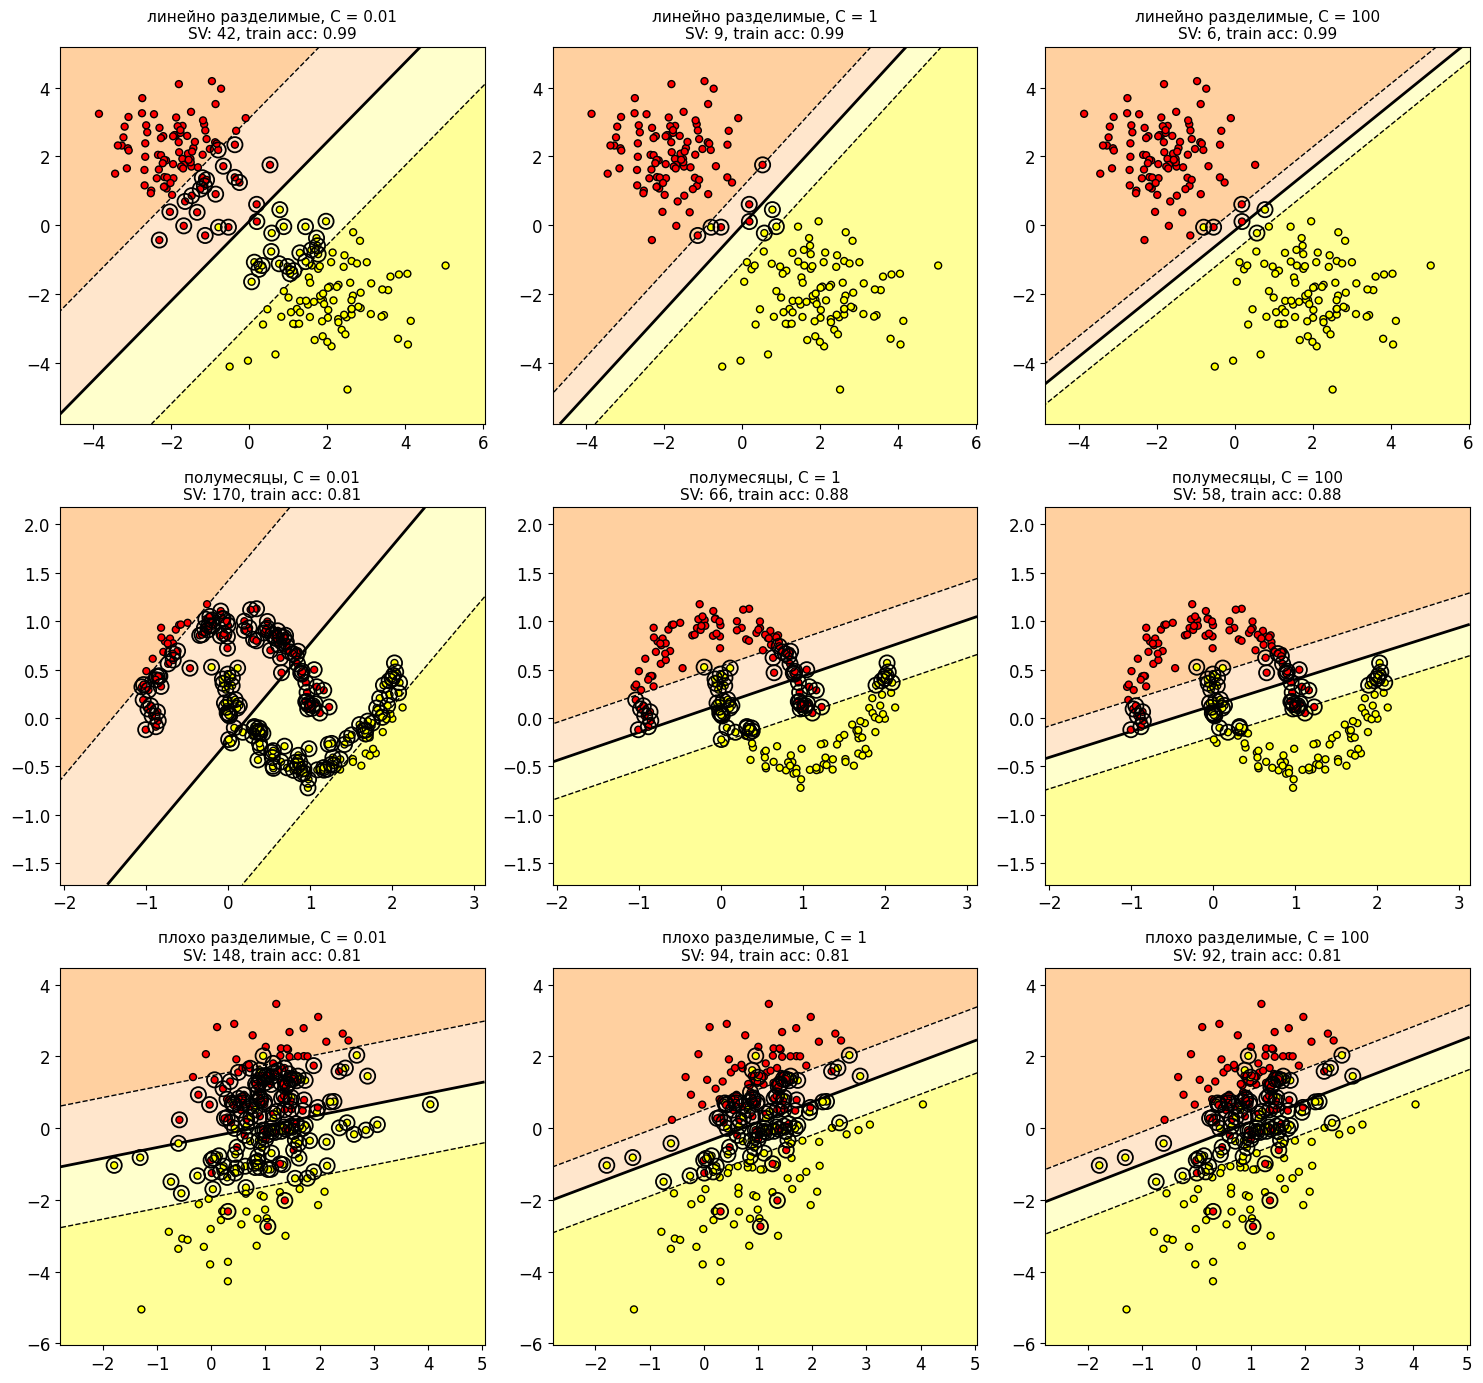

In [22]:
def plot_ax(model, X, y, ax, title=''):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-1e9, -1, 0, 1, 1e9], colors=['#ffd0a0', '#ffe6cc', '#ffffcc', '#ffff99'], zorder=0)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', s=25, zorder=2)
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='black', linewidths=1.3, zorder=3)
    acc = (model.predict(X) == y).mean()
    ax.set_title(f'{title}\nSV: {len(sv)}, train acc: {acc:.2f}', fontsize=11)
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)

Cs = [0.01, 1, 100]
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
for row, (name, (X, y)) in zip(axes, datasets.items()):
    for ax, C in zip(row, Cs):
        plot_ax(LinearSVM(C=C).fit(X, y), X, y, ax, f'{name}, C = {C}')
plt.tight_layout()
plt.show()

Кружками обведены опорные векторы; сплошная линия — $f(\boldsymbol x) = 0$, пунктир — границы коридора $f(\boldsymbol x) = \pm 1$.

**Число опорных векторов в зависимости от $C$.** Пройдёмся по логарифмической сетке. Заодно проверим, что опорные векторы по критерию активности совпадают с объектами, у которых множитель $\alpha_n > 0$, и выведем ширину коридора $2/\lVert\boldsymbol w\rVert$:

расхождений «активно» vs «alpha > 0»: 0


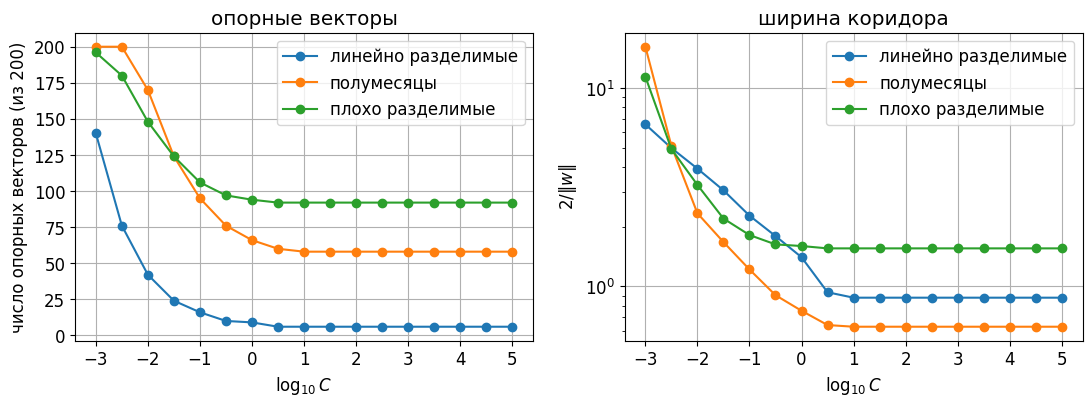

In [23]:
C_grid = np.logspace(-3, 5, 17)
n_sv = {name: [] for name in datasets}
width = {name: [] for name in datasets}
mismatch = 0
for name, (X, y) in datasets.items():
    for C in C_grid:
        m = LinearSVM(C=C).fit(X, y)
        n_sv[name].append(len(m.support_))
        width[name].append(2 / np.linalg.norm(m.weights_))
        mismatch += len(set(m.support_) ^ set(np.where(m.alpha_ > 1e-6 * m.alpha_.max())[0]))
print('расхождений «активно» vs «alpha > 0»:', mismatch)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in datasets:
    axes[0].plot(np.log10(C_grid), n_sv[name], 'o-', label=name)
    axes[1].plot(np.log10(C_grid), width[name], 'o-', label=name)
axes[0].set(xlabel='$\\log_{10} C$', ylabel='число опорных векторов (из 200)', title='опорные векторы')
axes[1].set(xlabel='$\\log_{10} C$', ylabel='$2 / \\|w\\|$', title='ширина коридора', yscale='log')
for ax in axes: ax.grid(True); ax.legend()
plt.show()

**Число опорных векторов и $C$.** Во всех трёх случаях число SV **монотонно убывает** с ростом $C$ и затем выходит на плато. Критерий «ограничение активно» совпал с критерием «$\alpha_n > 0$» во всех 51 обучениях (0 расхождений), то есть опорные векторы — это ровно объекты с ненулевыми двойственными переменными.

Объяснение:

- **Маленькое $C$** — нарушения дешёвые, и выгоднее уменьшать $\lVert\boldsymbol w\rVert$, расширяя коридор (правый график: ширина $2/\lVert\boldsymbol w\rVert$ при $C = 10^{-3}$ в 7–25 раз больше, чем на плато). В широкий коридор попадает почти вся выборка, а каждый объект внутри коридора имеет $\xi_n > 0$ и активное ограничение, то есть является опорным: 140–200 SV из 200.
- **Растёт $C$** — нарушения дорожают, коридор сужается, объекты выходят из него, и SV становится меньше.
- **Плато.** Начиная с $C \approx 1$–$10$ решение перестаёт меняться. Слагаемое $C\sum\xi_n$ доминирует, и задача фактически превращается в минимизацию суммарного нарушения $\sum \xi_n$, решение которой от $C$ уже не зависит. Нижняя граница числа SV у каждой выборки своя:
  - **линейно разделимые**: всего **6 SV**, решение с «жёстким» зазором держится на нескольких точках на границах коридора. (Train accuracy 0.99: в выборке есть пара «выбросов» чужого класса, они тоже остаются опорными);
  - **полумесяцы**: **58 SV**. Прямая принципиально не может разделить полумесяцы, около 24 объектов (12%) всегда на чужой стороне, а у ошибающихся объектов $\xi_n > 1$, и они всегда опорные;
  - **плохо разделимые**: **92 SV** — больше всех. 15% меток перевёрнуты случайно (`flip_y=0.15`), и много объектов неустранимо лежат внутри коридора или на чужой стороне.

Итак, число опорных векторов отражает «сложность» выборки для линейной модели: чем больше перекрытие классов, тем больше объектов определяют решение. На картинках это видно и качественно: при $C = 0.01$ коридор широкий, и опорными являются десятки точек. При $C = 100$ коридор узкий, и в случае разделимых облаков его держат лишь несколько крайних точек.

### Квадратичная разделяющая поверхность

Преобразование $\phi(x_1, x_2) = (x_1, x_2, x_1^2, x_1x_2, x_2^2)$ передаём в параметр `transform`: модель учится в 5-мерном пространстве, а на плоскости граница — кривая второго порядка. Проверим на полумесяцах и на «кольцах» (`make_circles`, как на анимации из п. 2.5), которые прямой не разделить вовсе:

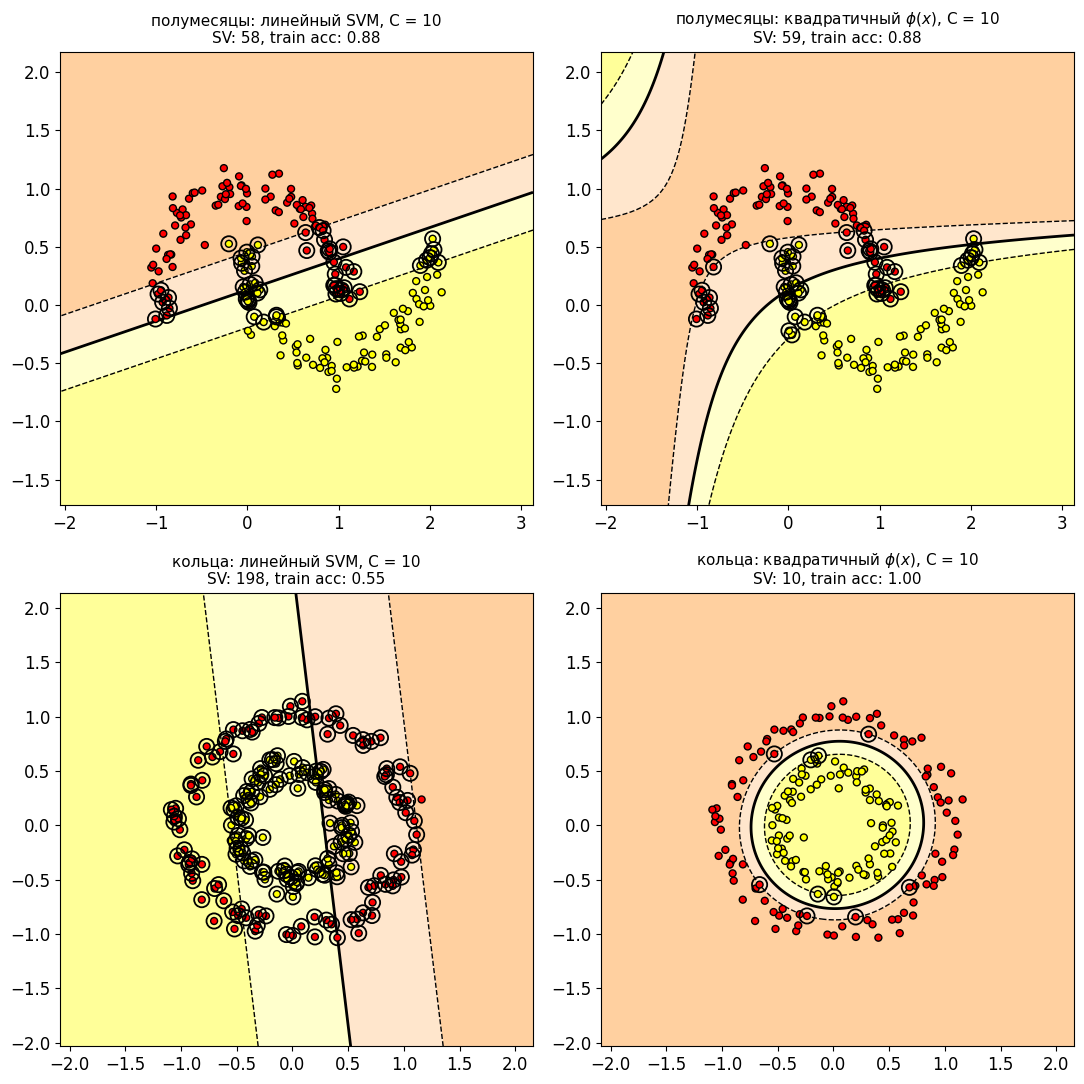

кольца, веса при (x1, x2, x1^2, x1x2, x2^2): [ 0.41  0.04 -5.8   0.31 -5.87]  b = 3.47


In [24]:
from sklearn.datasets import make_circles

def quad_features(X):
    X = np.asarray(X)
    return np.c_[X, X[:, 0]**2, X[:, 0] * X[:, 1], X[:, 1]**2]

X4, y4 = make_circles(n_samples=200, noise=0.08, factor=0.5, random_state=1)
y4s = 2 * y4 - 1

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for row, (name, X, y) in zip(axes, [('полумесяцы', X2, y2s), ('кольца', X4, y4s)]):
    plot_ax(LinearSVM(C=10).fit(X, y), X, y, row[0], f'{name}: линейный SVM, C = 10')
    plot_ax(LinearSVM(C=10, transform=quad_features).fit(X, y), X, y, row[1], f'{name}: квадратичный $\\phi(x)$, C = 10')
plt.tight_layout()
plt.show()

m_circ = LinearSVM(C=10, transform=quad_features).fit(X4, y4s)
print('кольца, веса при (x1, x2, x1^2, x1x2, x2^2):', m_circ.weights_.round(2), ' b =', round(m_circ.bias_, 2))

**Выводы по квадратичному преобразованию.**

- **Кольца.** Линейный SVM беспомощен (accuracy 0.55, почти все 198 объектов опорные), а квадратичный разделяет выборку **идеально** (accuracy 1.00) всего на **10 опорных векторах**. Выученные веса $\approx (0.41, 0.04, -5.80, 0.31, -5.87)$, $b \approx 3.47$: коэффициенты при $x_1^2$ и $x_2^2$ почти равны, а при $x_1, x_2, x_1x_2$ малы. Граница $-5.8(x_1^2 + x_2^2) + 3.47 \approx 0$ — это **окружность** радиуса $\approx\sqrt{3.47/5.8} \approx 0.77$, ровно между кольцами радиусов 0.5 и 1. Это в точности сценарий анимации из п. 2.5: в пространстве $\phi(\boldsymbol x)$ классы разделяет плоскость.
- **Полумесяцы.** Граница стала кривой второго порядка (гиперболой), но точность не выросла (0.88). Квадратичных функций недостаточно: S-образной границе нужен как минимум **кубический** член. Это видно в задании 3: полиномиальное ядро степени 3 даёт 0.99.

Явное преобразование признаков работает, но требует угадать нужный вид $\phi$ и быстро раздувает число признаков (для степени $p$ и $d$ признаков их $\binom{d+p}{p}$). Ядра из задания 3 снимают обе проблемы.

## 3. Двойственный переход и ядровой SVM

### 3.1. Двойственная задача

Задачу из раздела 2 называют **прямой**. У любой задачи оптимизации с ограничениями есть **двойственная** задача Лагранжа (см. [двойственность в оптимизации](https://en.wikipedia.org/wiki/Duality_(optimization)) и конспект лекций): в ней оптимизируются *двойственные переменные* — множители Лагранжа $\alpha_n$, по одному на каждый объект выборки. Для выпуклых задач QP, к которым относится SVM, оптимум двойственной задачи совпадает с оптимумом прямой, но двойственная форма удобнее: в ней признаки входят только через скалярные произведения, а это открывает путь к ядрам (п. 3.3).

Двойственная задача SVM:

$$
\begin{gathered}
\sum_{n} \alpha_n - \frac{1}{2}\sum_{n}\sum_{n'} \alpha_{n}\alpha_{n'}\, y_{n}y_{n'}\, \boldsymbol x_{n}^T\boldsymbol x_{n'} \to \max_{\boldsymbol\alpha} \\
\text{при: } \quad 0 \le \alpha_n \le C, \quad n = 1, \dots, N; \qquad \sum_{n} \alpha_n y_n = 0
\end{gathered}
$$

Как её читать:

- переменная $\alpha_n$ «прикреплена» к объекту $\boldsymbol x_n$ и играет роль «нажима» объекта на границу коридора;
- объект — **опорный вектор** тогда и только тогда, когда $\alpha_n > 0$: только эти объекты влияют на границу;
- верхняя граница $\alpha_n \le C$ — то же самое «ограничение цены ошибки» $C$, что и в прямой задаче.

Чтобы отдать задачу солверу, перепишем её как **минимизацию** $\frac{1}{2}\boldsymbol\alpha^T P \boldsymbol\alpha + \boldsymbol q^T \boldsymbol\alpha$ (проверяйте размеры!):

- $P_{nn'} = y_n y_{n'} \, \boldsymbol x_n^T \boldsymbol x_{n'}$, матрица $N \times N$;
- $q = (-1, \dots, -1)^T$;
- двойные неравенства $0 \le \alpha_n \le C$ — это $N$ пар неравенств $-\alpha_n \le 0$ и $\alpha_n \le C$: матрица $G = \begin{pmatrix} -I \\ I \end{pmatrix}$ размера $2N \times N$ и вектор $h = (0, \dots, 0, \; C, \dots, C)^T$;
- равенство $\sum_n \alpha_n y_n = 0$ — это $A = \boldsymbol y^T$ (одна строка) и $b = (0)$.

### 3.2. Предсказание и восстановление $b$

Предсказание для нового объекта $\boldsymbol x$ вычисляется через скалярные произведения с объектами обучающей выборки:

$$\hat{y}(\boldsymbol x) = \operatorname{sign}\left(\sum_{n} \alpha_n y_n \, \boldsymbol x^T \boldsymbol x_n + b\right),$$

причём суммировать достаточно только по опорным векторам — у остальных $\alpha_n = 0$.

Параметр $b$ из двойственной задачи напрямую не находится, но для любого опорного объекта, классифицируемого без ошибки, верно

$$y_n = \sum_{n'} \alpha_{n'} y_{n'} \, \boldsymbol x_n^T \boldsymbol x_{n'} + b,$$

откуда для одного такого объекта $b = y_n - \sum_{n'} \alpha_{n'} y_{n'} \boldsymbol x_n^T \boldsymbol x_{n'}$. Если есть ошибки классификации, значение $b$ **усредняют по всем опорным векторам**:

$$b = \frac{1}{|\mathrm{SV}|} \sum_{n \in \mathrm{SV}} \left(y_n - \sum_{n'} \alpha_{n'} y_{n'} \boldsymbol x_n^T \boldsymbol x_{n'}\right).$$

Интуиция: суммарные ошибки «в положительную» и «в отрицательную» стороны примерно компенсируются, и усреднение даёт устойчивую оценку. На практике: возьмите объекты с $\alpha_n > \varepsilon$ (например, $\varepsilon = 10^{-5}$) и усредните по ним.

### 3.3. Ядра, или неявное преобразование признаков

Ключевое наблюдение: и в задаче п. 3.1, и в правиле предсказания признаки входят **только в виде скалярных произведений** $\boldsymbol x^T \boldsymbol x'$. Значит, вместо явного вычисления $\phi(\boldsymbol x)$ можно всюду подставить функцию

$$k(\boldsymbol x, \boldsymbol x') = \phi(\boldsymbol x)^T \phi(\boldsymbol x'),$$

называемую **ядром**. Ядро — «мера похожести» объектов: заменив все произведения $\boldsymbol x_n^T \boldsymbol x_{n'}$ на $k(\boldsymbol x_n, \boldsymbol x_{n'})$, получаем SVM с нелинейной разделяющей поверхностью, хотя решается всё та же QP-задача. Вычислять $\phi$ явно не нужно (а её образ может лежать в пространстве огромной или даже бесконечной размерности) — в этом и состоит **ядровой трюк**.

Стандартные ядра:

- линейное: $k(\boldsymbol x, \boldsymbol x') = \boldsymbol x^T \boldsymbol x'$;
- полиномиальное степени $p$: $k(\boldsymbol x, \boldsymbol x') = (\boldsymbol x^T \boldsymbol x' + 1)^p$;
- гауссовское (RBF): $k(\boldsymbol x, \boldsymbol x') = \exp(-\gamma \lVert\boldsymbol x - \boldsymbol x'\rVert^2)$; чем меньше $\gamma$, тем «глаже» граница.

Совет: матрицу ядра $K$ с элементами $K_{nn'} = k(\boldsymbol x_n, \boldsymbol x_{n'})$ посчитайте один раз до обучения и переиспользуйте в `decision_function`. Для больших $N$ матрицы QP-задачи получаются разреженными — cvxopt умеет работать с [разреженными матрицами](https://cvxopt.org/userguide/matrices.html).

In [25]:
def linear_kernel(X1, X2):
    # k(x, x') = x^T x';  возвращает матрицу (n1, n2)
    return X1 @ X2.T

def poly_kernel(X1, X2, p=2):
    # k(x, x') = (x^T x' + 1)^p
    return (X1 @ X2.T + 1.0) ** p

def rbf_kernel(X1, X2, gamma=1.0):
    # k(x, x') = exp(-gamma * ||x - x'||^2)
    sq1 = np.sum(X1 ** 2, axis=1)[:, None]   # ||x||^2  столбцом, (n1, 1)
    sq2 = np.sum(X2 ** 2, axis=1)[None, :]   # ||x'||^2 строкой, (1, n2)
    return np.exp(-gamma * (sq1 + sq2 - 2.0 * X1 @ X2.T))

# проверка: на диагонали RBF-матрицы стоят единицы (расстояние до себя равно нулю)
K = rbf_kernel(X1, X1, gamma=1.0)
print('размер:', K.shape, '| диагональ:', np.diag(K)[:5])

размер: (200, 200) | диагональ: [1. 1. 1. 1. 1.]


### Скелет класса `DualSVM`

Интерфейс тот же, что у `LinearSVM`: `fit` обучает, `decision_function` возвращает $\sum_n \alpha_n y_n k(\boldsymbol x, \boldsymbol x_n) + b$, `predict` — его знак:

In [26]:
from sklearn.base import BaseEstimator

class DualSVM(BaseEstimator):
    def __init__(self, C=1.0, kernel=None):
        self.C = C
        self.kernel = kernel if kernel is not None else linear_kernel

    def fit(self, X, y):
        # обучение через двойственную QP-задачу (п. 3.1); переменные — alpha
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        N = len(self.y_)
        K = self.kernel(self.X_, self.X_)

        P = np.outer(self.y_, self.y_) * K + 1e-8 * np.eye(N)  # крошечная регуляризация для устойчивости солвера
        q = -np.ones(N)
        G = np.vstack([-np.eye(N), np.eye(N)])                 # -alpha <= 0,  alpha <= C
        h = np.r_[np.zeros(N), self.C * np.ones(N)]
        A = self.y_[None, :]                                   # sum alpha_n y_n = 0
        sol = solvers.qp(matrix(P), matrix(q), matrix(G), matrix(h), matrix(A), matrix(0.0))

        self.alpha_ = np.array(sol['x']).ravel()
        # порог «alpha > 0» берём относительно max(alpha): абсолютный 1e-5 слишком груб при C ~ 1e-3,
        # а порог ~C слишком велик при больших C (там alpha опорных векторов могут быть << C)
        sv = self.alpha_ > 1e-6 * self.alpha_.max()
        self.support_ = np.where(sv)[0]
        self.support_vectors_ = self.X_[sv]
        eps = 1e-5 * self.C

        # b: y_n - sum_n' alpha_n' y_n' k(x_n, x_n') по опорным векторам (п. 3.2).
        # Точно это равенство выполнено для объектов на границе коридора (0 < alpha < C);
        # объекты с alpha = C могут лежать внутри коридора / ошибаться и смещают оценку,
        # поэтому усредняем по «граничным» SV, а если таких нет — по всем SV.
        margin = sv & (self.alpha_ < self.C - eps)
        idx = margin if margin.any() else sv
        self.bias_ = np.mean(self.y_[idx] - K[idx] @ (self.alpha_ * self.y_))
        return self

    def decision_function(self, X):
        # f(x) = sum_n alpha_n y_n k(x, x_n) + b, суммируем только по опорным векторам
        K = self.kernel(np.asarray(X, dtype=float), self.support_vectors_)
        coef = self.alpha_[self.support_] * self.y_[self.support_]
        return K @ coef + self.bias_

    def predict(self, X):
        return np.sign(self.decision_function(X))

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 3. Двойственный SVM и ядра</h2>

1. Реализуйте процедуру обучения ядрового SVM (`DualSVM`) при помощи QP-солвера.
2. Протестируйте ядровой SVM на случайных двумерных выборках (удобно взять те же три, что и в задании 2). Покажите на плоскости разделяющие поверхности, границы коридора $f(\boldsymbol x) = \pm 1$ и опорные векторы. Попробуйте ядра:
   - линейное: $k(x, x') = x^T x'$;
   - полиномиальное: $k(x, x') = (x^T x' + 1)^p$ с различными степенями $p = 2, 3, \dots$;
   - гауссовское RBF: $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.
3. Как ведёт себя SVM с полиномиальным ядром при увеличении $C$ и степени ядра $p$?
4. Как ведёт себя SVM с RBF-ядром при вариации $C$ и $\gamma$ (поварьируйте параметры по логарифмической сетке)? Какие значения параметров приводят к переобучению, а какие — к слишком грубой модели? На выборке «полумесяцы» сравните линейное, полиномиальное и RBF-ядра.


## ✍️ Решение задания 3

Реализация `DualSVM` — в ячейке со скелетом выше. Два комментария к реализации:

- к матрице $P$ добавлена диагональ $10^{-8} I$: для линейного ядра $P$ вырождена (ранг $\le d = 2$), и солверу так спокойнее; на решение это не влияет;
- сдвиг $b$ усредняется по опорным векторам **на границе коридора** ($0 < \alpha_n < C$): только для них равенство из п. 3.2 точное. Объекты с $\alpha_n = C$ лежат внутри коридора или на чужой стороне, и их включение в среднее смещает $b$ (это видно в проверке ниже).

**Проверка корректности:** с линейным ядром двойственная задача должна дать ту же гиперплоскость, что и прямая. Восстановим $\boldsymbol w = \sum_n \alpha_n y_n \boldsymbol x_n$ и сравним с `LinearSVM`:

In [27]:
from functools import partial

for name, (X, y) in datasets.items():
    p = LinearSVM(C=1).fit(X, y)
    d = DualSVM(C=1).fit(X, y)
    w_dual = (d.alpha_ * d.y_) @ d.X_
    sv_all = d.alpha_ > 1e-5
    b_all = np.mean(d.y_[sv_all] - linear_kernel(d.X_[sv_all], d.X_) @ (d.alpha_ * d.y_))
    print(f'{name:20s} прямая: w = {p.weights_.round(4)}, b = {p.bias_:+.4f}, SV = {len(p.support_)} | '
          f'двойственная: w = {w_dual.round(4)}, b = {d.bias_:+.4f}, SV = {len(d.support_)} | b по всем SV = {b_all:+.4f}')

линейно разделимые   прямая: w = [ 1.1069 -0.8966], b = -0.0145, SV = 9 | двойственная: w = [ 1.1069 -0.8966], b = -0.0145, SV = 9 | b по всем SV = +0.0260
полумесяцы           прямая: w = [ 0.7385 -2.5457], b = +0.3611, SV = 66 | двойственная: w = [ 0.7385 -2.5457], b = +0.3611, SV = 66 | b по всем SV = +0.2538


плохо разделимые     прямая: w = [ 0.6193 -1.0873], b = -0.4463, SV = 94 | двойственная: w = [ 0.6193 -1.0873], b = -0.4463, SV = 94 | b по всем SV = -0.4216


Прямая и двойственная задачи дают **одинаковые** $\boldsymbol w$, $b$ и одинаковое число опорных векторов на всех трёх выборках, так что обе реализации согласованы. Последний столбец показывает, зачем понадобилась поправка в вычислении $b$. Если усреднять по *всем* опорным векторам, как в п. 3.2, сдвиг заметно смещается (на полумесяцах $0.25$ вместо $0.36$). Чем больше объектов с $\alpha_n = C$, тем сильнее смещение.

### Разные ядра на трёх выборках ($C = 1$)

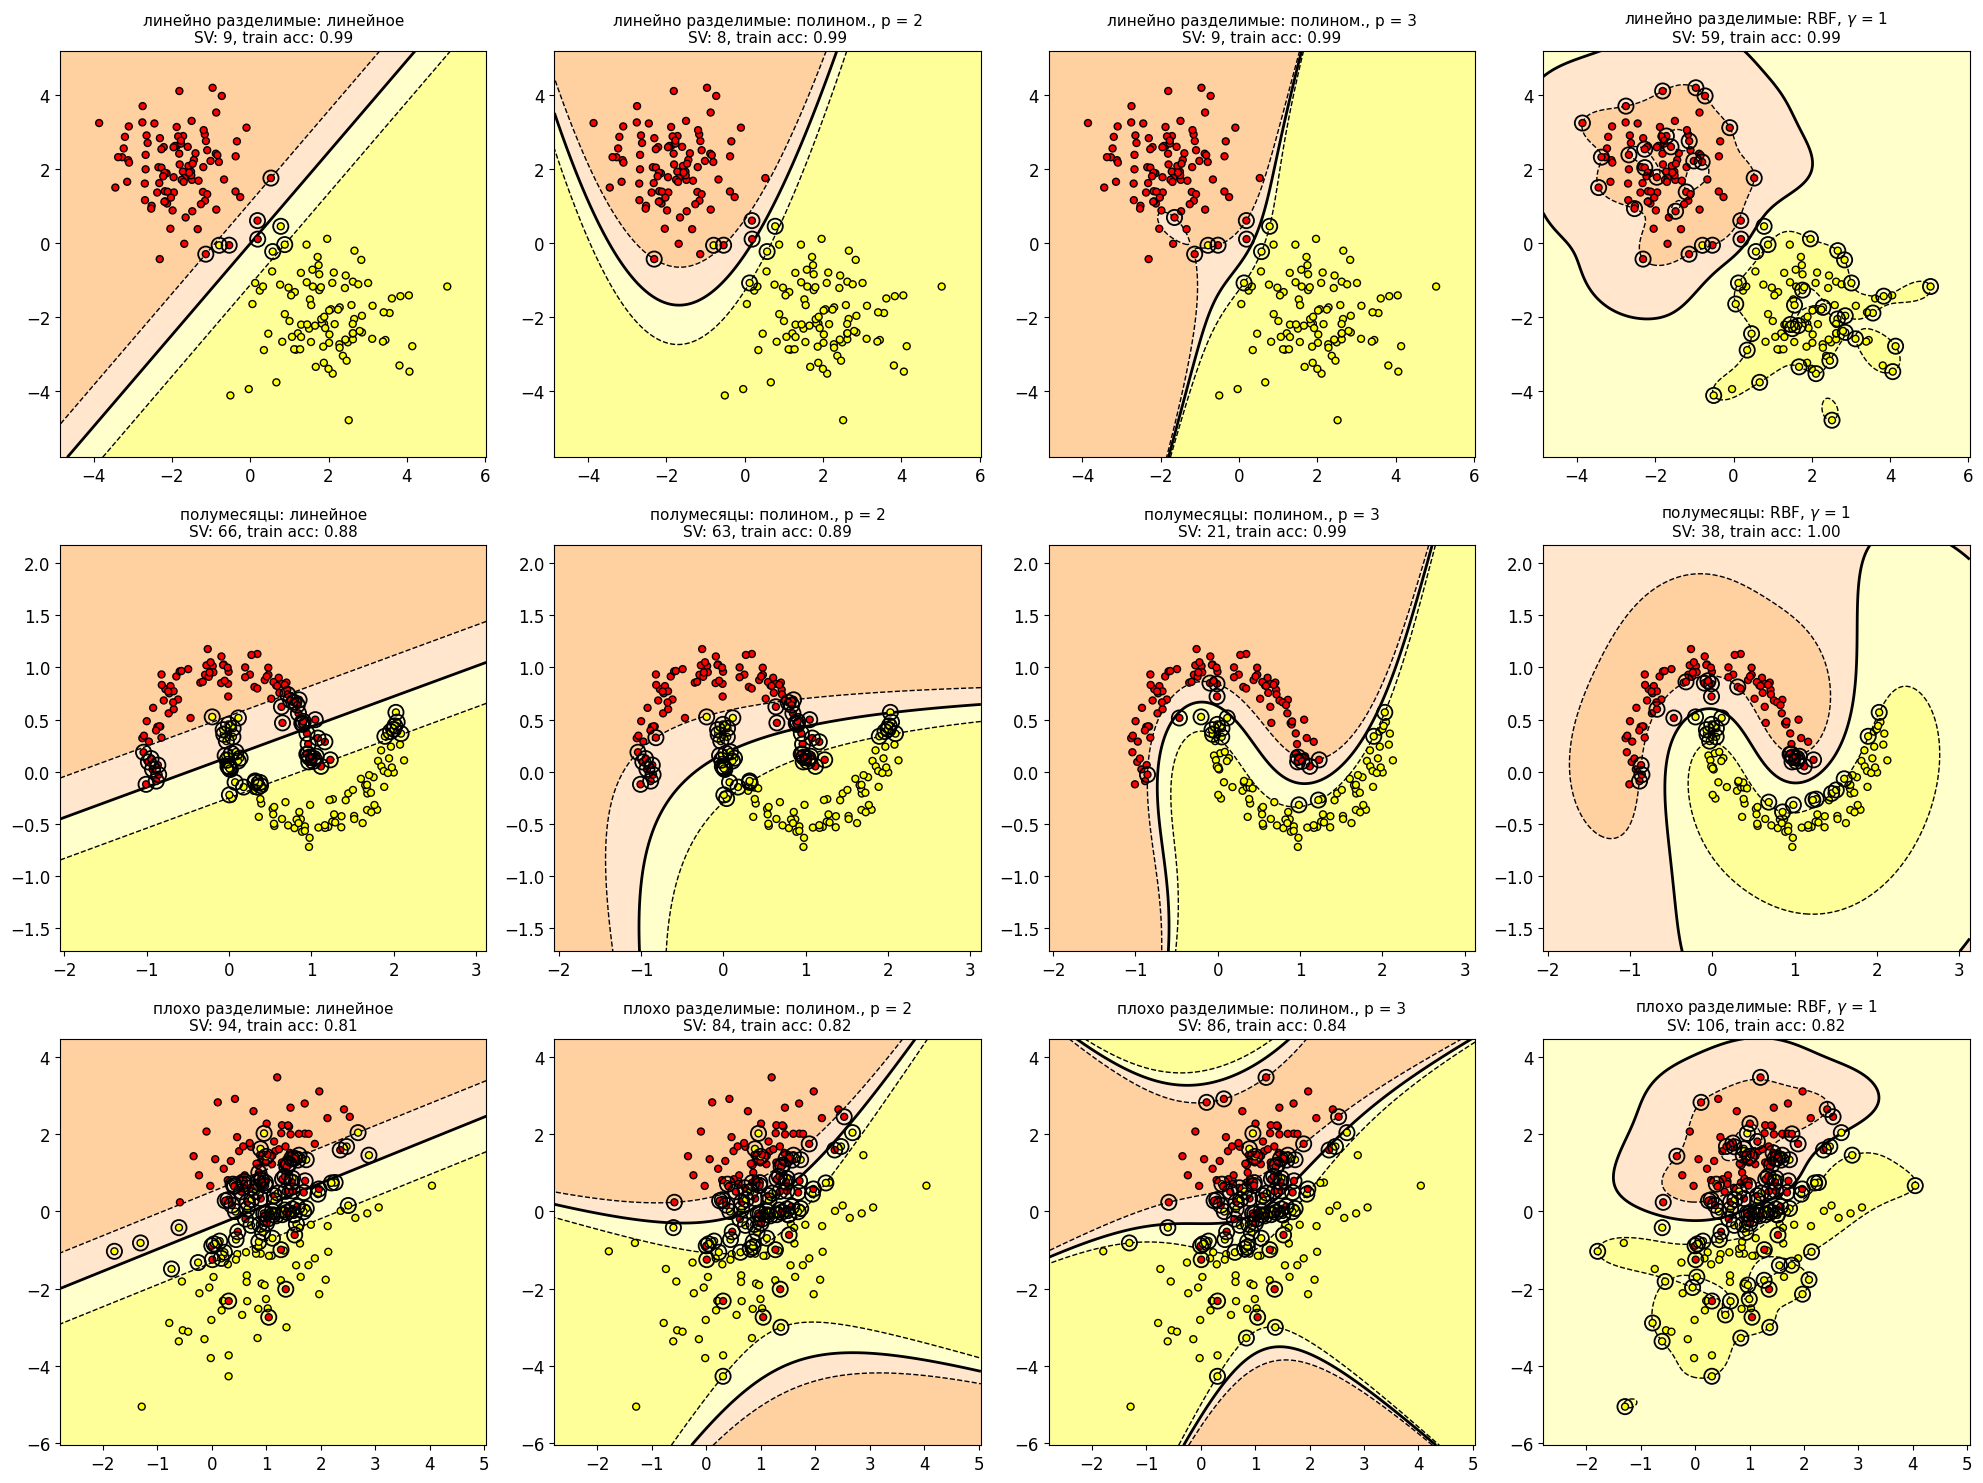

In [28]:
kernels = {'линейное': linear_kernel,
           'полином., p = 2': partial(poly_kernel, p=2),
           'полином., p = 3': partial(poly_kernel, p=3),
           'RBF, $\\gamma$ = 1': partial(rbf_kernel, gamma=1.0)}

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
for row, (name, (X, y)) in zip(axes, datasets.items()):
    for ax, (kname, k) in zip(row, kernels.items()):
        plot_ax(DualSVM(C=1, kernel=k).fit(X, y), X, y, ax, f'{name}: {kname}')
plt.tight_layout()
plt.show()

**Наблюдения ($C = 1$):**

- **Линейно разделимые.** Все ядра дают 0.99 на train. Линейное и полиномиальные ядра обходятся 8–9 опорными векторами. RBF с $\gamma = 1$ строит «облакообразную» границу вокруг каждого класса и использует 59 SV, то есть модель избыточно сложна для простой задачи. По принципу Оккама здесь стоит выбрать линейное ядро.
- **Полумесяцы.** Линейное ядро (0.88) и полиномиальное степени 2 (0.89) не справляются, по той же причине, что и в задании 2. Полиномиальное ядро степени 3 (0.99, 21 SV) и RBF (1.00, 38 SV) повторяют S-образную форму классов.
- **Плохо разделимые.** Все ядра дают 0.81–0.84. Нелинейные ядра выигрывают пару процентов на train, только «выгибая» границу вокруг шумовых точек, то есть подстраиваясь под перевёрнутые метки. У полиномиального ядра степени 3 появились лишние области далеко от данных (сверху и снизу): это артефакты полиномиальной экстраполяции, полином неограниченно растёт вдали от выборки.

### Полиномиальное ядро: влияние $C$ и степени $p$ (полумесяцы)

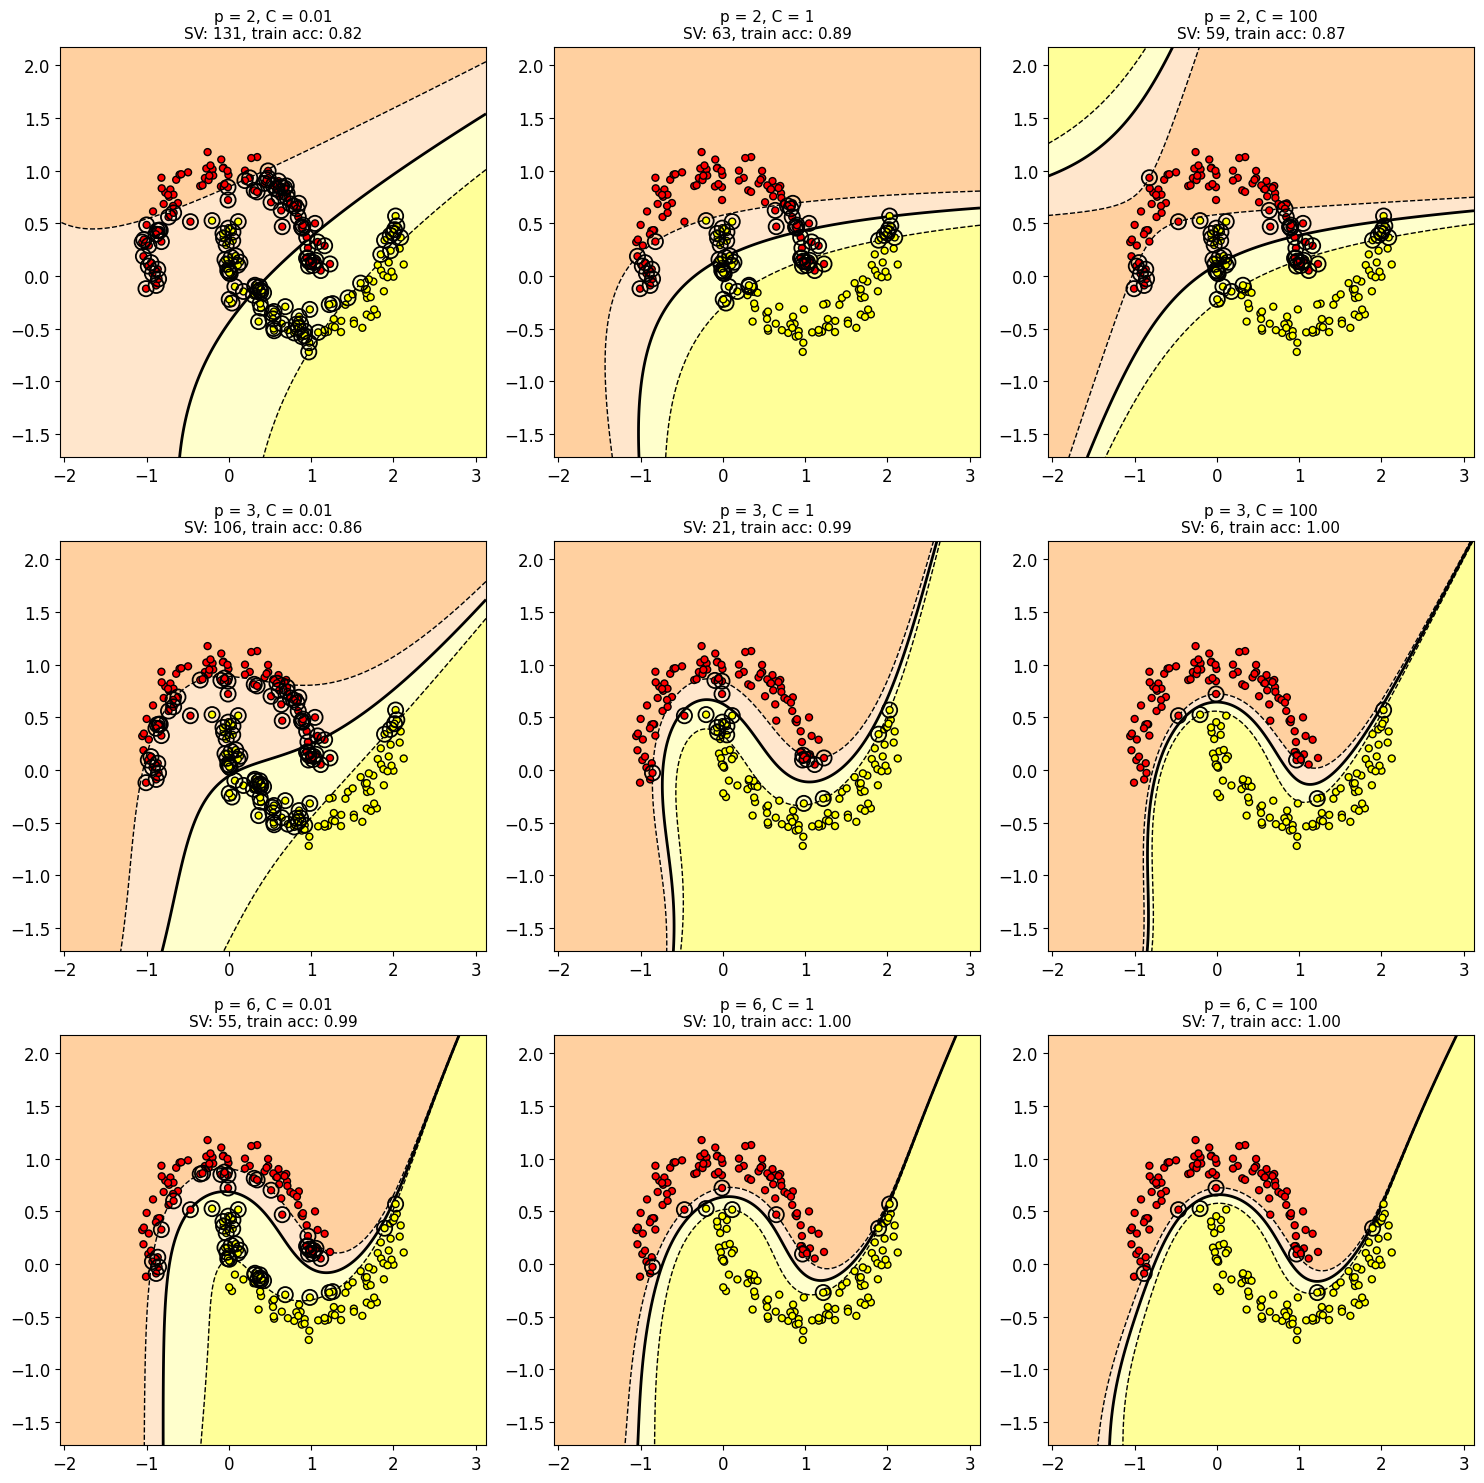

In [29]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for row, p in zip(axes, [2, 3, 6]):
    for ax, C in zip(row, [0.01, 1, 100]):
        plot_ax(DualSVM(C=C, kernel=partial(poly_kernel, p=p)).fit(X2, y2s), X2, y2s, ax, f'p = {p}, C = {C}')
plt.tight_layout()
plt.show()

**Полиномиальное ядро: влияние $C$ и $p$.**

- **Рост $C$** (по строкам слева направо) ослабляет регуляризацию: коридор сужается, опорных векторов становится меньше (для $p = 3$: 106 → 21 → 6), граница всё точнее облегает обучающую выборку.
- **Рост $p$** (по столбцам сверху вниз) повышает гибкость: $p = 2$ не может разделить полумесяцы ни при каком $C$ (граница — гипербола, accuracy ≤ 0.89). При $p = 3$ выборка разделяется уже с $C = 1$, а $p = 6$ справляется даже при $C = 0.01$.
- **$C$ и $p$ взаимосвязаны.** Значения ядра $(\boldsymbol x^T\boldsymbol x' + 1)^p$ быстро растут с $p$, так что признаки в неявном пространстве становятся «крупнее», и то же $C$ означает более слабую регуляризацию. Поэтому при $p = 6$ даже $C = 0.01$ ведёт себя как большое $C$ при $p = 2$. Подбирать $C$ нужно заново для каждой степени.
- **Риск переобучения.** При больших $p$ и $C$ коридор становится очень узким, граница проходит вплотную к отдельным точкам (6–7 SV держат всю модель), а вдали от данных её ветви уходят в бесконечность по непредсказуемым направлениям (см. правый верхний угол графиков для $p = 3, 6$). Для новых данных за пределами обучающего облака такая модель ненадёжна.

### RBF-ядро: влияние $C$ и $\gamma$

Сначала картинки на полумесяцах, затем — количественно: чтобы переобучение было видно в цифрах, возьмём более шумные полумесяцы (`noise=0.3`) и разобьём их на train/test.

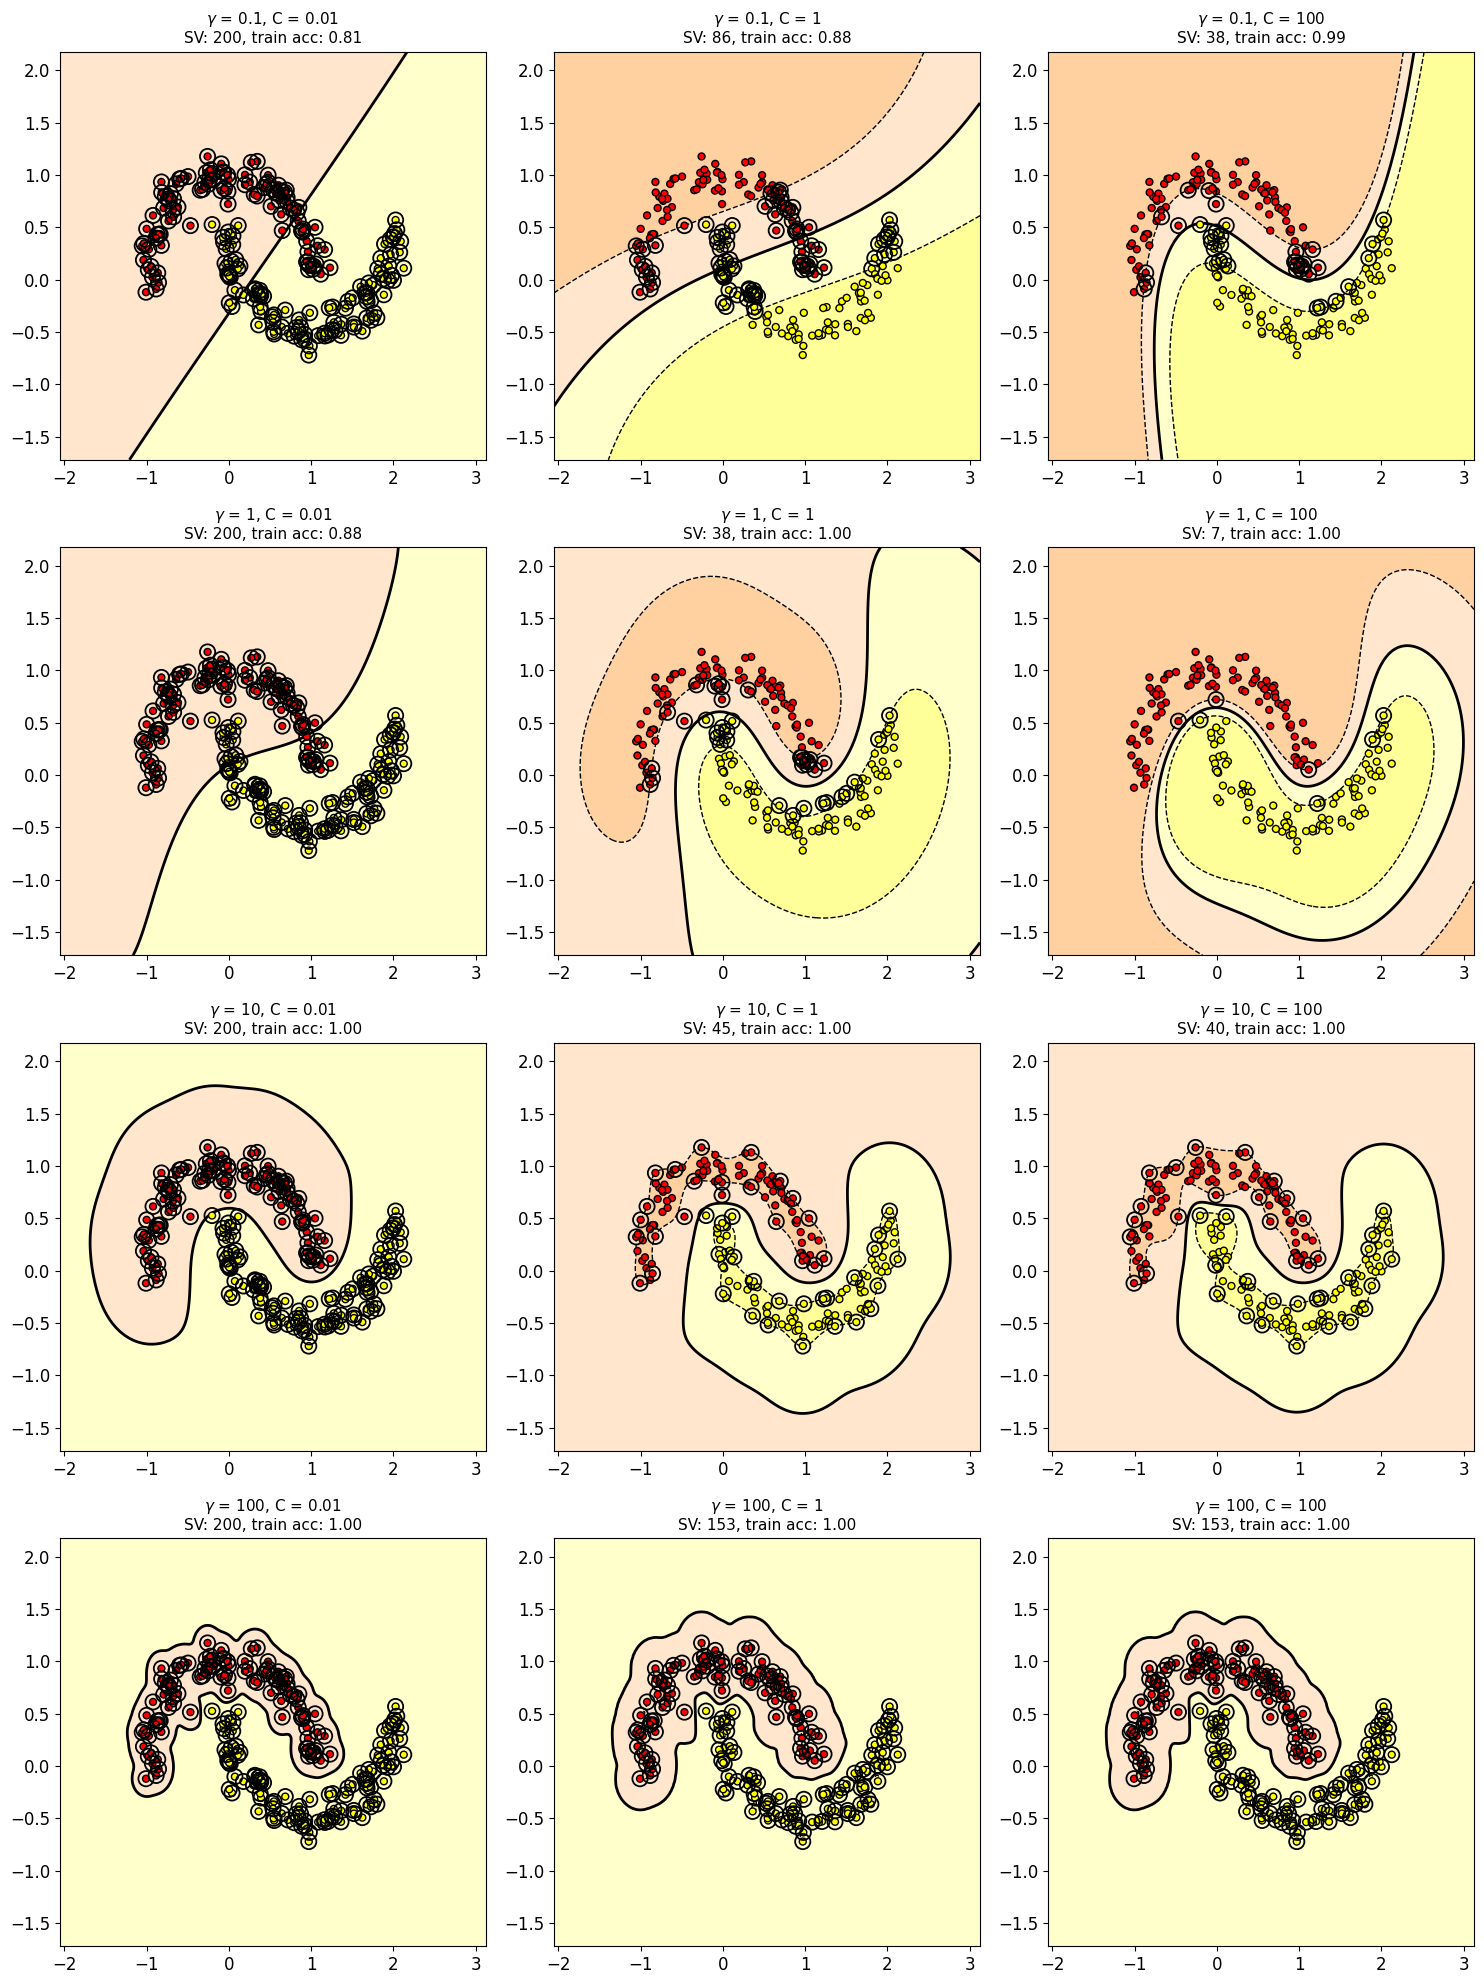

In [30]:
fig, axes = plt.subplots(4, 3, figsize=(15, 20))
for row, gamma in zip(axes, [0.1, 1, 10, 100]):
    for ax, C in zip(row, [0.01, 1, 100]):
        plot_ax(DualSVM(C=C, kernel=partial(rbf_kernel, gamma=gamma)).fit(X2, y2s), X2, y2s, ax,
                f'$\\gamma$ = {gamma}, C = {C}')
plt.tight_layout()
plt.show()

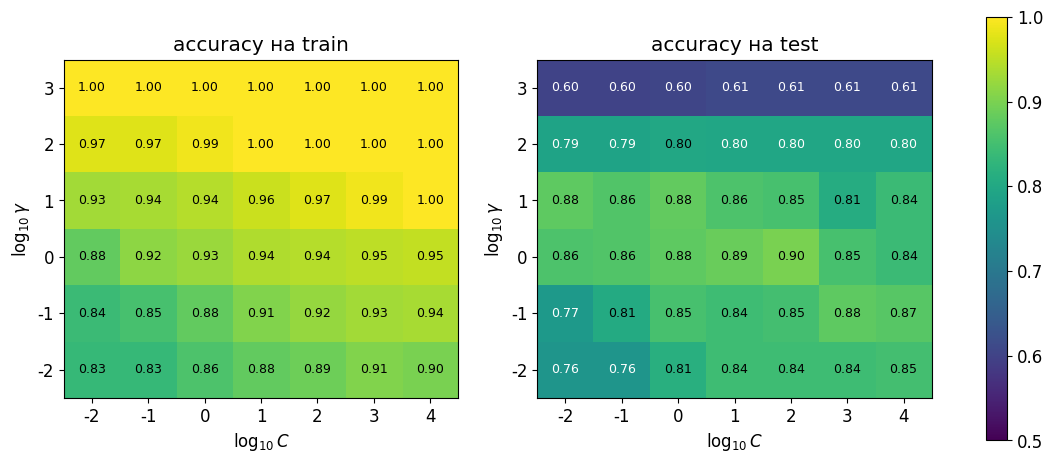

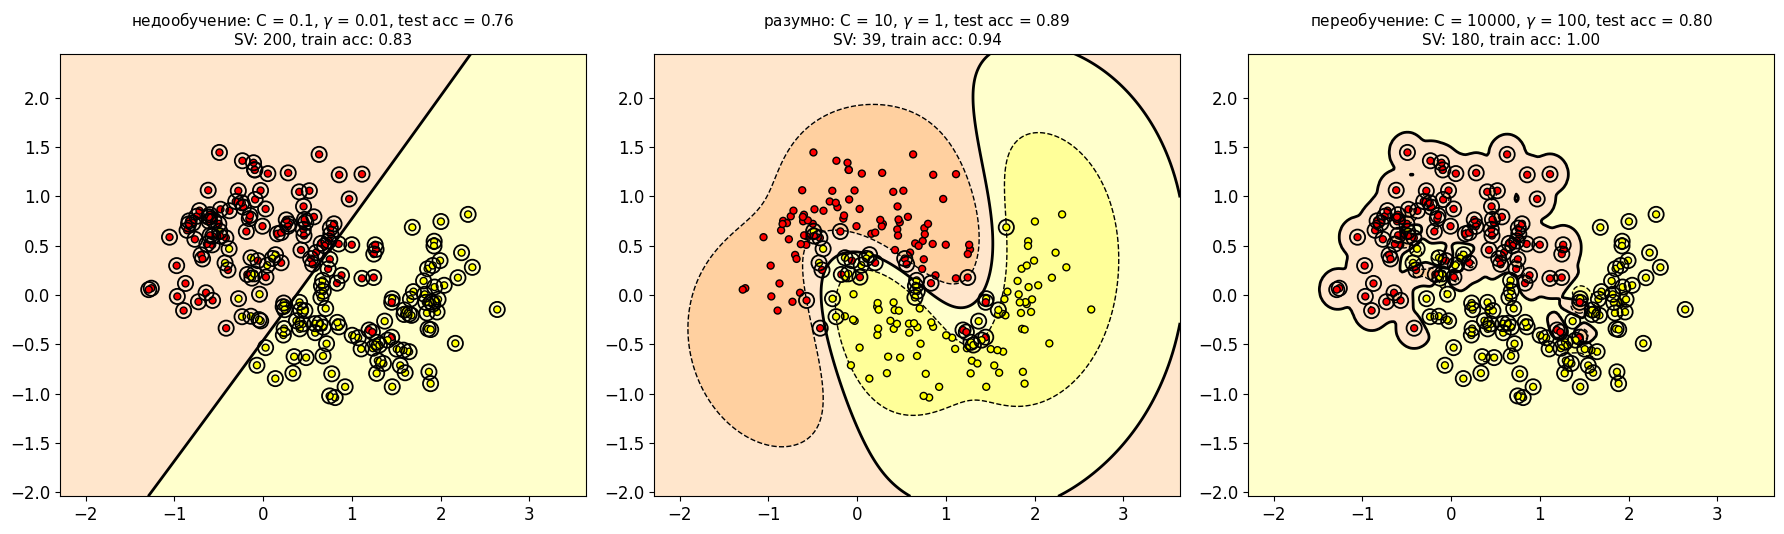

In [31]:
from sklearn.model_selection import train_test_split

Xn, yn = make_moons(n_samples=400, noise=0.3, random_state=2)
yn = 2 * yn - 1
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.5, random_state=0, stratify=yn)

C_rbf = np.logspace(-2, 4, 7)
g_rbf = np.logspace(-2, 3, 6)
acc_tr = np.zeros((len(g_rbf), len(C_rbf)))
acc_te = np.zeros_like(acc_tr)
for i, g in enumerate(g_rbf):
    for j, C in enumerate(C_rbf):
        m = DualSVM(C=C, kernel=partial(rbf_kernel, gamma=g)).fit(Xn_tr, yn_tr)
        acc_tr[i, j] = (m.predict(Xn_tr) == yn_tr).mean()
        acc_te[i, j] = (m.predict(Xn_te) == yn_te).mean()

def heatmap(ax, A, xs, ys, title, xlabel='$\\log_{10} C$', ylabel='$\\log_{10} \\gamma$'):
    im = ax.imshow(A, origin='lower', cmap='viridis', vmin=0.5, vmax=1.0)
    ax.set_xticks(range(len(xs)), [f'{np.log10(v):g}' for v in xs])
    ax.set_yticks(range(len(ys)), [f'{np.log10(v):g}' for v in ys])
    for (i, j), v in np.ndenumerate(A):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v < 0.8 else 'black', fontsize=9)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
heatmap(axes[0], acc_tr, C_rbf, g_rbf, 'accuracy на train')
im = heatmap(axes[1], acc_te, C_rbf, g_rbf, 'accuracy на test')
fig.colorbar(im, ax=axes)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (C, g, label) in zip(axes, [(0.1, 0.01, 'недообучение'), (10, 1, 'разумно'), (1e4, 100, 'переобучение')]):
    m = DualSVM(C=C, kernel=partial(rbf_kernel, gamma=g)).fit(Xn_tr, yn_tr)
    plot_ax(m, Xn_tr, yn_tr, ax, f'{label}: C = {C:g}, $\\gamma$ = {g:g}, test acc = {(m.predict(Xn_te) == yn_te).mean():.2f}')
plt.tight_layout()
plt.show()

**RBF-ядро: влияние $C$ и $\gamma$.**

$\gamma$ задаёт радиус влияния опорного вектора ($\sim 1/\sqrt{\gamma}$), а $C$ — силу регуляризации.

- **Слишком маленькое $\gamma$ (0.01–0.1) и маленькое $C$ — недообучение.** Каждый объект «видит» почти всю выборку, ядро близко к константе плюс линейная часть, и граница почти прямая. Train и test одинаково низкие (0.76–0.83), а опорными являются все 200 объектов: коридор огромен.
- **Слишком большое $\gamma$ (100–1000) — переобучение.** Каждая точка окружена собственным «островком». Train accuracy = 1.00 при любом $C$, но test падает до 0.80 при $\gamma = 100$ и до **0.60** при $\gamma = 1000$. Почти все объекты становятся опорными (153 из 200 на чистых полумесяцах), потому что каждый поддерживает только себя. Вдали от данных функция решения равна просто $b$, и модель «по умолчанию» относит всё к одному классу (правая картинка).
- **Рост $C$** при фиксированном $\gamma$ монотонно поднимает train accuracy (тепловая карта train растёт вправо-вверх). На test есть оптимум: при $\gamma = 1$ точность 0.86 → **0.90** (при $C = 100$) → 0.84.
- На тепловой карте test хорошие значения идут **по диагонали**: большему $\gamma$ нужен меньший $C$, и наоборот ($\gamma = 10$ лучше всего при $C \le 1$, $\gamma = 0.1$ — при $C = 10^3$). Оба параметра регулируют сложность модели, и подбирать их нужно **совместно** по логарифмической сетке. Лучшая зона — $\gamma \sim 1$, $C \sim 1$–$100$ (test 0.86–0.90).

### Сравнение ядер на полумесяцах

Для честного сравнения для каждого ядра подберём гиперпараметры 5-кратной кросс-валидацией (`GridSearchCV` работает с нашим классом, потому что он наследует `BaseEstimator`) на шумных полумесяцах из train, а качество измерим на test:

In [32]:
from sklearn.model_selection import GridSearchCV

grids = {
    'линейное':       {'kernel': [linear_kernel], 'C': np.logspace(-2, 3, 6)},
    'полиномиальное': {'kernel': [partial(poly_kernel, p=p) for p in (2, 3, 4, 5)], 'C': np.logspace(-2, 3, 6)},
    'RBF':            {'kernel': [partial(rbf_kernel, gamma=g) for g in np.logspace(-2, 2, 5)], 'C': np.logspace(-2, 3, 6)},
}
def kname(k):
    return 'linear' if not isinstance(k, partial) else f'{k.func.__name__}({k.keywords})'

for name, grid in grids.items():
    gs = GridSearchCV(DualSVM(), grid, cv=5, scoring='accuracy').fit(Xn_tr, yn_tr)
    test_acc = (gs.predict(Xn_te) == yn_te).mean()
    print(f'{name:15s} лучшие параметры: C = {gs.best_params_["C"]:g}, {kname(gs.best_params_["kernel"]):28s} '
          f'CV acc = {gs.best_score_:.3f}, test acc = {test_acc:.3f}')

линейное        лучшие параметры: C = 10, linear                       CV acc = 0.885, test acc = 0.845


полиномиальное  лучшие параметры: C = 0.1, poly_kernel({'p': 5})        CV acc = 0.925, test acc = 0.870


RBF             лучшие параметры: C = 100, rbf_kernel({'gamma': np.float64(1.0)}) CV acc = 0.935, test acc = 0.900


**Сравнение ядер на полумесяцах** (шумные полумесяцы, гиперпараметры подобраны по CV):

| Ядро | Лучшие параметры | CV accuracy | Test accuracy |
|---|---|:---:|:---:|
| линейное | $C = 10$ | 0.885 | 0.845 |
| полиномиальное | $p = 5$, $C = 0.1$ | 0.925 | 0.870 |
| RBF | $\gamma = 1$, $C = 100$ | **0.935** | **0.900** |

Линейное ядро проигрывает, потому что не способно описать изогнутую границу. Полиномиальное ядро описывает форму классов, но проигрывает RBF: его граница плохо ведёт себя вдали от данных, а гиперпараметры $p$ и $C$ сильно связаны. RBF — самый гибкий и «локальный» вариант, он лучше всех по обеим метрикам и стандартно используется по умолчанию. Его гибкость требует аккуратного подбора $(C, \gamma)$: см. тепловую карту выше, где неудачные $\gamma$ дают 0.60–0.80.

## 4. Практика: SVM на реальных данных (диагностика болезней сердца)

До сих пор все данные были синтетическими: два признака, никаких пропусков, одинаковый масштаб. Реальные данные устроены иначе: в них нет строки заголовка, пропуски закодированы символом `?`, часть признаков — категории, а масштабы различаются на порядки. В этом задании вы пройдёте полный цикл работы аналитика: **загрузка → разведка → подготовка → обучение и настройка собственной модели**.

Данные — [Heart Disease, клиника Кливленда](https://archive.ics.uci.edu/dataset/45/heart+disease) из репозитория UCI: результаты обследования 303 пациентов. По 13 признакам (возраст, давление, холестерин, результаты ЭКГ и стресс-тестов и др.) нужно предсказать, есть ли у пациента заболевание сердца, — бинарная классификация с понятным прикладным смыслом: такие модели используются как скрининговая поддержка решений врача.

### 4.1. Загрузка и разведка данных (`pandas`)

Оригинальный файл распространяется **без строки заголовка**, а пропуски в нём обозначены символом `?` — с этим и разберётся `pandas`. Словарь признаков:

| Признак | Описание |
|:---:|:---|
| `age` | возраст, лет |
| `sex` | пол (1 — мужской, 0 — женский) |
| `cp` | тип грудной боли (1–4) |
| `trestbps` | артериальное давление в покое, мм рт. ст. |
| `chol` | уровень холестерина, мг/дл |
| `fbs` | сахар в крови натощак выше 120 мг/дл (1 — да, 0 — нет) |
| `restecg` | результаты ЭКГ в покое (0–2) |
| `thalach` | достигнутая максимальная частота пульса |
| `exang` | стенокардия, вызванная нагрузкой (1 — да, 0 — нет) |
| `oldpeak` | депрессия сегмента ST на ЭКГ при нагрузке |
| `slope` | наклон пикового сегмента ST (1–3) |
| `ca` | число крупных сосудов, окрашенных при флуороскопии (0–3) |
| `thal` | результат сцинтиграфии с таллием: 3 — норма, 6 — фиксированный дефект, 7 — обратимый дефект |
| `num` | **целевой признак**: диагноз (0 — здоров, 1–4 — степень заболевания) |

Загрузите таблицу функцией [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) с параметрами `names=...` (имена столбцов) и `na_values='?'` (так обозначены пропуски). Минимальный набор команд разведки:

- `df.head()`, `df.shape` — первые строки и размер таблицы;
- `df.info()`, `df.isna().sum()` — типы столбцов и где пропуски;
- `df.describe()` — базовые статистики числовых столбцов;
- `df['num'].value_counts()` — сколько здоровых и больных (баланс классов).

In [33]:
import pandas as pd

columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
try:
    df = pd.read_csv(url, names=columns, na_values='?')          # загрузка из интернета
except Exception:
    df = pd.read_csv('heart.csv', names=columns, na_values='?')  # копия рядом с ноутбуком

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [34]:
# Начало разведки: размер данных и пропуски по столбцам
print('размер таблицы:', df.shape)
df.isna().sum()

размер таблицы: (303, 14)


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

### 4.2. Подготовка данных: чек-лист

Прежде чем подавать данные в SVM, их нужно привести к виду «числовая матрица $X$ + вектор меток $y \in \{+1, -1\}$». Пройдитесь по чек-листу (каждый шаг прокомментируйте в отчёте — что и почему вы делаете):

1. **Целевая переменная**: в `num` значения 0–4. Приведите её к бинарной метке: `y = (df['num'] > 0).astype(int)`, затем `y = 2 * y - 1` (получатся $-1$ и $+1$). Сам столбец `num` уберите из признаков.
2. **Пропуски**: их всего шесть строк в `ca` и `thal` — удалите эти строки (`dropna`) или заполните (медиана, мода). Обоснуйте выбор: сколько процентов данных вы теряете?
3. **Категориальные признаки**: `cp`, `restecg`, `slope`, `thal` — это **категории, а не числа** (большее значение не означает «больше»): закодируйте их через `pd.get_dummies(...)`. Признаки `sex`, `fbs`, `exang` уже бинарные — оставьте как есть.
4. **Разбить данные**: [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) с параметрами `test_size=0.2, stratify=y, random_state=...` — тестовая выборка нужна для честной оценки качества.
5. **Масштабировать признаки**: [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) приводит каждый признак к нулевому среднему и единичному отклонению. Обучать скейлер нужно **только на train**, а к test применять уже обученный (`transform`). Почему масштабирование критично для SVM? Вспомните: модель строится на скалярных произведениях и норме $\lVert\boldsymbol w\rVert$, а признаки «холестерин» (сотни мг/дл) и «пол» (0/1) различаются на 2–3 порядка — без выравнивания масштаба «громкий» признак заглушит остальные.

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 4. SVM на реальных данных</h2>

1. Выполните загрузку, разведку и подготовку данных по чек-листу п. 4.2. В отчёте покажите таблицу до и после подготовки и поясните каждый шаг.
2. Обучите **свой** `LinearSVM` (из задания 2) на подготовленных данных. Подберите $C$ по логарифмической сетке $10^{-3}, \dots, 10^{5}$: посчитайте accuracy на train и test для каждого значения и изобразите оба графика в зависимости от $\log_{10} C$. Выберите лучшее $C$ и объясните выбор.
3. Обучите **свой** `DualSVM` с RBF-ядром: подберите пару $(C, \gamma)$ по логарифмической сетке (удобно построить тепловую карту качества). Стало ли лучше, чем с линейным SVM? На какой модели и параметрах остановитесь?
4. Проверьте себя: обучите [`sklearn.svm.SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) с `kernel='linear'` и `kernel='rbf'` на тех же данных и гиперпараметрах — качество должно получиться близким к вашему. Если различие велико — ищите ошибку в реализации.
5. Ответьте на вопросы в отчёте:
   - что произойдёт с качеством вашего SVM, если **не** масштабировать признаки? Проверьте экспериментально и объясните результат;
   - какие признаки сильнее всего влияют на диагноз? Для линейной SVM естественная мера важности признака $j$ — модуль веса $\lvert w_j \rvert$: отсортируйте признаки по важности и дайте клиническую интерпретацию — согласуется ли результат с медицинской интуицией (что важнее: боль в груди, возраст или холестерин?);
   - какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от $C$? Много ли пациентов оказываются «на границе» диагноза?

In [35]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

## ✍️ Решение задания 4

### 4.1. Разведка

In [36]:
print('размер таблицы:', df.shape)
df.info()

размер таблицы: (303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [37]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00


In [38]:
print('пропуски:\n', df[df.isna().any(axis=1)])
print('\nраспределение num:\n', df['num'].value_counts().sort_index())
print('\nздоров / болен:', (df['num'] == 0).sum(), '/', (df['num'] > 0).sum())

пропуски:
       age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca  thal  num  
87     1.0  0.0   NaN    0  
166    1.0  NaN   3.0    0  
192    2.0  NaN   7.0    1  
266    2.0  0.0   NaN    2  
287    2.0  NaN   7.0    0  
302    1.0  NaN   3.0    0  

распределение num:
 num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

здоров / болен: 164 / 139


**Что показала разведка:**

- 303 пациента, 13 признаков и целевой `num`. После `na_values='?'` все столбцы числовые (`float64`).
- **Пропуски** только в `ca` (4) и `thal` (2): ровно 6 строк, в каждой по одному пропуску.
- **Баланс классов**: 164 здоровых (54%) и 139 больных (46%), то есть классы почти сбалансированы, и accuracy — разумная метрика. Градации болезни 1–4 мы объединим в «болен».
- **Масштабы** различаются на порядки: `chol` 126–564, `trestbps` 94–200, `thalach` 71–202, а `sex`, `fbs`, `exang` равны 0/1, и `oldpeak` 0–6.2.
- `cp`, `restecg`, `slope`, `thal` записаны числами, но это **коды категорий** (например, `thal` = 3/6/7). Среднее `thal` = 4.73 бессмысленно, и такие признаки нужно кодировать one-hot.

### 4.2. Подготовка данных

In [39]:
# 1. Целевая переменная: 0 -> -1 (здоров), 1..4 -> +1 (болен)
# 2. Пропуски: удаляем строки
df_clean = df.dropna()
print(f'удалено строк: {len(df) - len(df_clean)} из {len(df)} ({(len(df) - len(df_clean)) / len(df):.1%})')

y = 2 * (df_clean['num'] > 0).astype(int).values - 1
X_df = df_clean.drop(columns='num')

# 3. Категориальные признаки -> one-hot
cat_cols = ['cp', 'restecg', 'slope', 'thal']
X_df = pd.get_dummies(X_df, columns=cat_cols, dtype=float)
print('признаков после one-hot:', X_df.shape[1])
X_df.head()

удалено строк: 6 из 303 (2.0%)
признаков после one-hot: 22


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


In [40]:
# 4. Разбиение train / test (стратифицированное)
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, stratify=y, random_state=42)

# 5. Масштабирование: скейлер обучаем только на train
scaler = StandardScaler().fit(X_train_df)
X_train = scaler.transform(X_train_df)
X_test = scaler.transform(X_test_df)
feature_names = X_df.columns.to_numpy()

print('train:', X_train.shape, ' test:', X_test.shape)
print('доля больных: train %.3f, test %.3f' % ((y_train == 1).mean(), (y_test == 1).mean()))
pd.DataFrame(X_train, columns=feature_names).describe().loc[['mean', 'std']].round(2)

train: (237, 22)  test: (60, 22)
доля больных: train 0.460, test 0.467


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
mean,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,...,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Пояснения к подготовке:**

1. **Целевая переменная**: `num > 0` → болен (+1), иначе здоров (−1). Столбец `num` из признаков удалён, иначе получилась бы утечка ответа.
2. **Пропуски**: строки удалены. Теряем 6 из 303 строк (**2%**), это пренебрежимо мало. Заполнение здесь сомнительно: `ca` и `thal` — одни из самых информативных признаков (см. ниже), и подставленная медиана исказила бы именно их.
3. **One-hot**: `cp` (4 значения), `restecg` (3), `slope` (3), `thal` (3) превратились в 13 бинарных столбцов. Вместе с 9 оставшимися признаками получилось **22 признака**. Признак `ca` (число поражённых сосудов, 0–3) оставлен числовым: порядок у него осмысленный, больше сосудов — хуже. Лишний столбец каждой группы (`drop_first`) не удаляли: L2-регуляризация SVM делает задачу корректной и при линейной зависимости столбцов, а полный набор проще интерпретировать.
4. **Разбиение**: 237 объектов в train и 60 в test. Благодаря стратификации доля больных одинакова (46%).
5. **Масштабирование**: `StandardScaler` обучен только на train, поэтому на train средние 0 и отклонения 1 (таблица выше). Test преобразован теми же параметрами, без подглядывания.

### 4.3. Свой `LinearSVM`: подбор $C$

Выбирать $C$ по тестовой выборке нечестно: тогда тестовая оценка перестаёт быть независимой (мы подогнали под неё гиперпараметр). Поэтому кроме train и test accuracy посчитаем **5-кратную кросс-валидацию на train** и выбирать будем по ней; test — только финальная проверка.

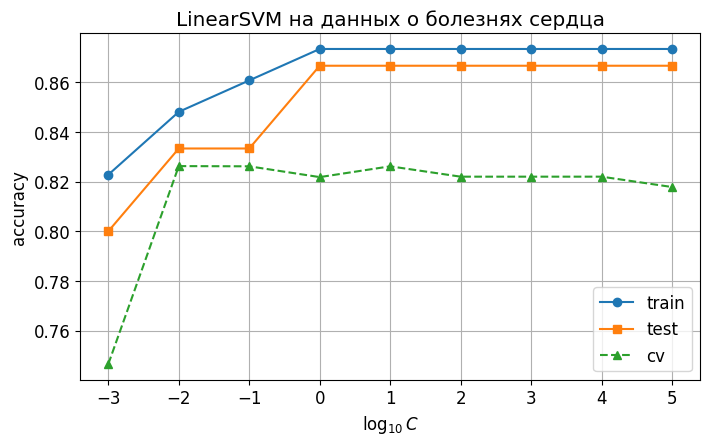

,C,train,test,cv,SV,SV доля
0,0.001,0.823,0.800,0.747,219,0.924
1,0.010,0.848,0.833,0.826,133,0.561
2,0.100,0.861,0.833,0.826,99,0.418
3,1.000,0.873,0.867,0.822,90,0.380
4,10.000,0.873,0.867,0.826,89,0.376
5,100.000,0.873,0.867,0.822,89,0.376
6,1000.000,0.873,0.867,0.822,89,0.376
7,10000.000,0.873,0.867,0.822,89,0.376
8,100000.000,0.873,0.867,0.818,89,0.376


In [41]:
C_lin = np.logspace(-3, 5, 9)
res_lin = []
for C in C_lin:
    m = LinearSVM(C=C).fit(X_train, y_train)
    res_lin.append({'C': C,
                    'train': accuracy_score(y_train, m.predict(X_train)),
                    'test': accuracy_score(y_test, m.predict(X_test)),
                    'cv': cross_val_score(LinearSVM(C=C), X_train, y_train, cv=5, scoring="accuracy").mean(),
                    'SV': len(m.support_),
                    'SV доля': len(m.support_) / len(y_train)})
res_lin = pd.DataFrame(res_lin)

plt.figure(figsize=(8, 4.5))
for col, st in [('train', 'o-'), ('test', 's-'), ('cv', '^--')]:
    plt.plot(np.log10(res_lin['C']), res_lin[col], st, label=col)
plt.xlabel('$\\log_{10} C$'); plt.ylabel('accuracy'); plt.title('LinearSVM на данных о болезнях сердца')
plt.grid(True); plt.legend()
plt.show()
res_lin.round(3)

In [42]:
best_C_lin = res_lin.loc[res_lin['cv'].idxmax(), 'C']
lin_best = LinearSVM(C=best_C_lin).fit(X_train, y_train)
print(f'лучшее C по CV: {best_C_lin:g}')
print(f'train acc = {accuracy_score(y_train, lin_best.predict(X_train)):.3f}, '
      f'test acc = {accuracy_score(y_test, lin_best.predict(X_test)):.3f}')

лучшее C по CV: 0.01
train acc = 0.848, test acc = 0.833


**Выбор $C$ для LinearSVM.**

- При $C = 10^{-3}$ регуляризация слишком сильная, и модель **недообучена**: коридор настолько широк, что 92% объектов — опорные, а train, CV и test заметно ниже (0.82 / 0.75 / 0.80).
- Начиная с $C \approx 10^{-2}$ качество выходит на **плато**: CV ≈ 0.82–0.83, test 0.83–0.87. При $C \ge 1$ решение вообще перестаёт меняться (те же 89 SV). Данные не разделимы линейно, поэтому при большом $C$ задача сводится к минимизации суммарного нарушения $\sum\xi_n$ (см. задание 2). Переобучения нет даже при $C = 10^5$: у линейной модели с 22 признаками слишком мало свободы, чтобы «запомнить» 237 пациентов.
- **Выбор: $C = 0.01$.** Это максимум CV-accuracy (0.826; разница с соседними $C$ — тысячные доли), и из равных по CV вариантов мы берём **наиболее регуляризованный** как самый простой и устойчивый. Test accuracy этой модели 0.833, у моделей с $C \ge 1$ — 0.867. Но это разница ровно в **2 пациента из 60**, а стандартная ошибка accuracy на 60 объектах $\approx\sqrt{0.85 \cdot 0.15 / 60} \approx 0.046$. Выбирать $C$ по такой разнице на test означало бы подгонку под тест.

### 4.4. Свой `DualSVM` с RBF-ядром: подбор $(C, \gamma)$

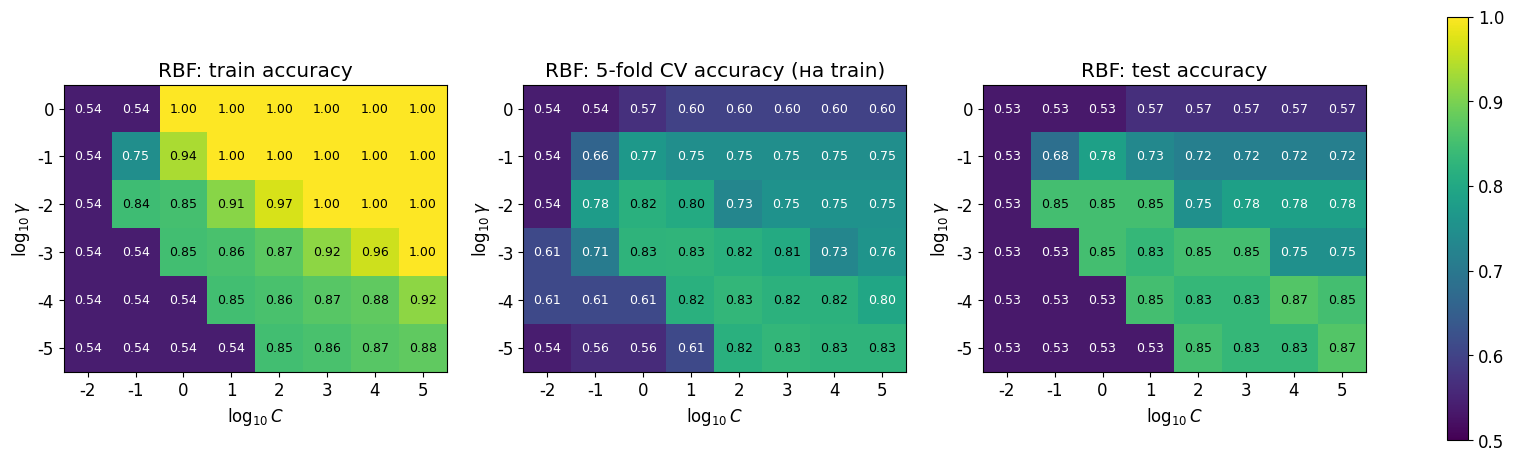

лучшие по CV: C = 1000, gamma = 1e-05, CV acc = 0.830
train acc = 0.857, test acc = 0.833, SV: 118 из 237


In [43]:
C_hd = np.logspace(-2, 5, 8)
g_hd = np.logspace(-5, 0, 6)
cv_hd = np.zeros((len(g_hd), len(C_hd)))
tr_hd, te_hd = np.zeros_like(cv_hd), np.zeros_like(cv_hd)
for i, g in enumerate(g_hd):
    for j, C in enumerate(C_hd):
        k = partial(rbf_kernel, gamma=g)
        cv_hd[i, j] = cross_val_score(DualSVM(C=C, kernel=k), X_train, y_train, cv=5, scoring="accuracy").mean()
        m = DualSVM(C=C, kernel=k).fit(X_train, y_train)
        tr_hd[i, j] = accuracy_score(y_train, m.predict(X_train))
        te_hd[i, j] = accuracy_score(y_test, m.predict(X_test))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
heatmap(axes[0], tr_hd, C_hd, g_hd, 'RBF: train accuracy')
heatmap(axes[1], cv_hd, C_hd, g_hd, 'RBF: 5-fold CV accuracy (на train)')
im = heatmap(axes[2], te_hd, C_hd, g_hd, 'RBF: test accuracy')
fig.colorbar(im, ax=axes)
plt.show()

i, j = np.unravel_index(cv_hd.argmax(), cv_hd.shape)
best_C_rbf, best_g_rbf = C_hd[j], g_hd[i]
rbf_best = DualSVM(C=best_C_rbf, kernel=partial(rbf_kernel, gamma=best_g_rbf)).fit(X_train, y_train)
print(f'лучшие по CV: C = {best_C_rbf:g}, gamma = {best_g_rbf:g}, CV acc = {cv_hd[i, j]:.3f}')
print(f'train acc = {accuracy_score(y_train, rbf_best.predict(X_train)):.3f}, '
      f'test acc = {accuracy_score(y_test, rbf_best.predict(X_test)):.3f}, '
      f'SV: {len(rbf_best.support_)} из {len(y_train)}')

**RBF-SVM на данных о болезнях сердца.**

- Тепловые карты повторяют картину из задания 3. При $\gamma \ge 0.1$ и большом $C$ train accuracy = **1.00**, но CV и test проваливаются до 0.57–0.75: это **сильное переобучение**. При маленьких $C$ модель вырождается в константу (0.54 — доля здоровых). При $\gamma = 1$ в 22-мерном пространстве объекты «далеко» друг от друга (типичное $\lVert \boldsymbol x - \boldsymbol x' \rVert^2 \approx 44$), и ядро почти диагональное: каждый пациент похож только на себя.
- Лучшие CV-значения (**0.82–0.83**) получаются в области маленьких $\gamma$ ($10^{-5}$–$10^{-3}$). Лучшая клетка — $C = 1000$, $\gamma = 10^{-5}$ (CV 0.830, test 0.833). Но при $\gamma\lVert\boldsymbol x - \boldsymbol x'\rVert^2 \ll 1$ RBF-ядро почти линейно: $e^{-\gamma\lVert\boldsymbol x - \boldsymbol x'\rVert^2} \approx 1 - \gamma\lVert\boldsymbol x\rVert^2 - \gamma\lVert\boldsymbol x'\rVert^2 + 2\gamma\,\boldsymbol x^T\boldsymbol x'$. Модель там фактически **линейный SVM** с эффективным $C_{\text{eff}} \approx 2\gamma C$. Поэтому лучший RBF и упирается в край сетки по $\gamma$: он «стремится» стать линейным.
- **Стало ли лучше?** Нет: CV 0.830 против 0.826 у линейного SVM, разница в пределах шума. Нелинейность не даёт выигрыша. В пространстве из 22 признаков классы разделяются примерно линейно, а остаток ошибок — это перекрытие классов, а не кривизна границы.
- **Итоговый выбор — `LinearSVM` с $C = 0.01$**: то же качество (CV 0.826, test 0.833), один гиперпараметр вместо двух, и он интерпретируем: веса $w_j$ прямо показывают вклад признаков (п. 4.6). Для медицинской задачи прозрачность модели — существенный плюс.

### 4.5. Проверка себя: `sklearn.svm.SVC`

In [44]:
rows = []
for C in C_lin:
    ours = LinearSVM(C=C).fit(X_train, y_train)
    sk = SVC(kernel='linear', C=C).fit(X_train, y_train)
    rows.append({'модель': 'linear', 'C': C, 'gamma': '-',
                 'test (наша)': accuracy_score(y_test, ours.predict(X_test)),
                 'test (sklearn)': accuracy_score(y_test, sk.predict(X_test)),
                 'SV (наша)': len(ours.support_), 'SV (sklearn)': sk.n_support_.sum(),
                 'совпадение предсказаний': (ours.predict(X_test) == sk.predict(X_test)).mean()})
for C in C_hd:
    for g in sorted({best_g_rbf, 0.01, 0.1}):
        ours = DualSVM(C=C, kernel=partial(rbf_kernel, gamma=g)).fit(X_train, y_train)
        sk = SVC(kernel='rbf', C=C, gamma=g).fit(X_train, y_train)
        rows.append({'модель': 'rbf', 'C': C, 'gamma': g,
                     'test (наша)': accuracy_score(y_test, ours.predict(X_test)),
                     'test (sklearn)': accuracy_score(y_test, sk.predict(X_test)),
                     'SV (наша)': len(ours.support_), 'SV (sklearn)': sk.n_support_.sum(),
                     'совпадение предсказаний': (ours.predict(X_test) == sk.predict(X_test)).mean()})
pd.DataFrame(rows).round(3)

,модель,C,gamma,test (наша),test (sklearn),SV (наша),SV (sklearn),совпадение предсказаний
0,linear,0.001,-,0.800,0.800,219,219,1.0
1,linear,0.010,-,0.833,0.833,133,133,1.0
2,linear,0.100,-,0.833,0.833,99,98,1.0
3,linear,1.000,-,0.867,0.867,90,90,1.0
4,linear,10.000,-,0.867,0.867,89,89,1.0
5,linear,100.000,-,0.867,0.867,89,89,1.0
6,linear,1000.000,-,0.867,0.867,89,89,1.0
7,linear,10000.000,-,0.867,0.867,89,88,1.0
8,linear,100000.000,-,0.867,0.867,89,88,1.0
9,rbf,0.010,0.00001,0.533,0.533,223,218,1.0


**Сравнение со `sklearn.svm.SVC`.** Предсказания на test **совпали на 100%** во всех 33 конфигурациях (9 линейных и 24 RBF), включая плохо обусловленные случаи $C = 10^5$. Число опорных векторов совпадает с точностью до 1–2 объектов. Это объекты с $\alpha_n$ почти ровно на границе $0$ или $C$, где решают допуски солверов: у libsvm $10^{-3}$, у нас $10^{-10}$. Реализация корректна.

*Эта проверка нашла ошибку в первой версии `DualSVM`.* Порог «$\alpha_n > 10^{-5} C$» при $C = 10^5$ равен 1 и отбрасывал настоящие опорные векторы с $\alpha_n < 1$. Совпадение с sklearn падало до 70% при $C = 10^5$, $\gamma = 0.1$. Сейчас порог взят относительно $\max_n \alpha_n$.

### 4.6. Вопросы

**Что будет без масштабирования?** Подадим моделям «сырые» признаки (one-hot уже есть, но `age`, `chol`, `trestbps`, `thalach` — в своих единицах). Сначала посмотрим на тех же гиперпараметрах, что и раньше, а затем — честно: **заново подберём** гиперпараметры по CV на сырых данных (оптимальные $C$ и $\gamma$ зависят от масштаба, и сравнивать модели с чужими гиперпараметрами было бы нечестно).

,модель,масштабирование,train,test
0,"LinearSVM, C=0.01",да,0.848,0.833
1,"LinearSVM, C=0.01",нет,0.814,0.833
2,"RBF, C=1000, gamma=1e-05",да,0.857,0.833
3,"RBF, C=1000, gamma=1e-05",нет,0.861,0.867


,модель,масштабирование,параметры,CV,test
0,LinearSVM,да,C=0.01,0.826,0.833
1,LinearSVM,нет,C=1,0.826,0.867
2,RBF,да,"C=1000, gamma=1e-05",0.830,0.833
3,RBF,нет,"C=1000, gamma=1e-05",0.806,0.867


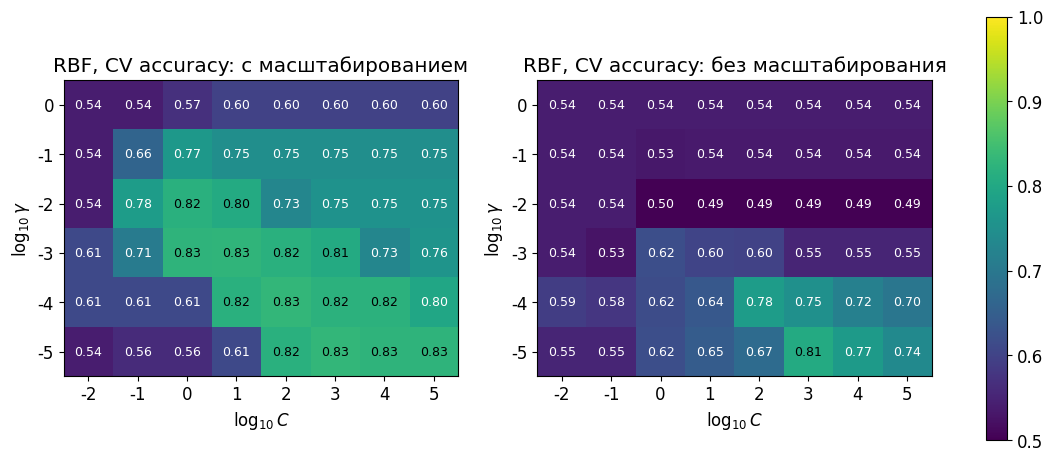

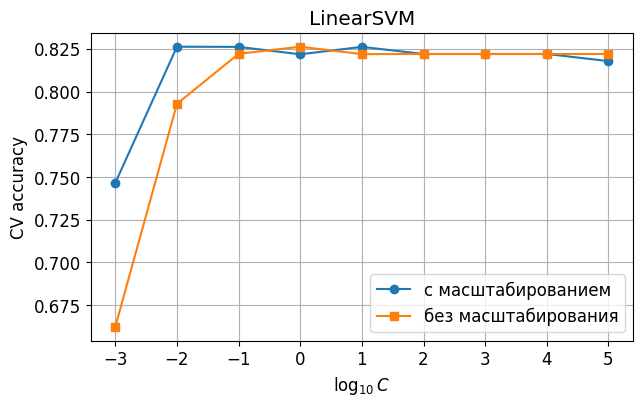

In [45]:
Xr_train, Xr_test = X_train_df.to_numpy(), X_test_df.to_numpy()

# (а) те же гиперпараметры, что выбраны на масштабированных данных
rows = []
for name, make in [(f'LinearSVM, C={best_C_lin:g}', lambda: LinearSVM(C=best_C_lin)),
                   (f'RBF, C={best_C_rbf:g}, gamma={best_g_rbf:g}',
                    lambda: DualSVM(C=best_C_rbf, kernel=partial(rbf_kernel, gamma=best_g_rbf)))]:
    for scaled, Xtr, Xte in [('да', X_train, X_test), ('нет', Xr_train, Xr_test)]:
        m = make().fit(Xtr, y_train)
        rows.append({'модель': name, 'масштабирование': scaled,
                     'train': accuracy_score(y_train, m.predict(Xtr)), 'test': accuracy_score(y_test, m.predict(Xte))})
display(pd.DataFrame(rows).round(3))

# (б) гиперпараметры заново подобраны по 5-fold CV на сырых данных
cv_lin_raw = [cross_val_score(LinearSVM(C=C), Xr_train, y_train, cv=5, scoring='accuracy').mean() for C in C_lin]
cv_rbf_raw = np.array([[cross_val_score(DualSVM(C=C, kernel=partial(rbf_kernel, gamma=g)), Xr_train, y_train,
                                        cv=5, scoring='accuracy').mean() for C in C_hd] for g in g_hd])
i, j = np.unravel_index(cv_rbf_raw.argmax(), cv_rbf_raw.shape)
C_lin_raw = C_lin[int(np.argmax(cv_lin_raw))]
m_lin_raw = LinearSVM(C=C_lin_raw).fit(Xr_train, y_train)
m_rbf_raw = DualSVM(C=C_hd[j], kernel=partial(rbf_kernel, gamma=g_hd[i])).fit(Xr_train, y_train)
display(pd.DataFrame([
    {'модель': 'LinearSVM', 'масштабирование': 'да', 'параметры': f'C={best_C_lin:g}',
     'CV': res_lin['cv'].max(), 'test': accuracy_score(y_test, lin_best.predict(X_test))},
    {'модель': 'LinearSVM', 'масштабирование': 'нет', 'параметры': f'C={C_lin_raw:g}',
     'CV': max(cv_lin_raw), 'test': accuracy_score(y_test, m_lin_raw.predict(Xr_test))},
    {'модель': 'RBF', 'масштабирование': 'да', 'параметры': f'C={best_C_rbf:g}, gamma={best_g_rbf:g}',
     'CV': cv_hd.max(), 'test': accuracy_score(y_test, rbf_best.predict(X_test))},
    {'модель': 'RBF', 'масштабирование': 'нет', 'параметры': f'C={C_hd[j]:g}, gamma={g_hd[i]:g}',
     'CV': cv_rbf_raw.max(), 'test': accuracy_score(y_test, m_rbf_raw.predict(Xr_test))},
]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
heatmap(axes[0], cv_hd, C_hd, g_hd, 'RBF, CV accuracy: с масштабированием')
im = heatmap(axes[1], cv_rbf_raw, C_hd, g_hd, 'RBF, CV accuracy: без масштабирования')
fig.colorbar(im, ax=axes)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(np.log10(C_lin), res_lin['cv'], 'o-', label='с масштабированием')
plt.plot(np.log10(C_lin), cv_lin_raw, 's-', label='без масштабирования')
plt.xlabel('$\\log_{10} C$'); plt.ylabel('CV accuracy'); plt.title('LinearSVM'); plt.grid(True); plt.legend()
plt.show()

In [46]:
# почему так: вклад признаков в квадрат расстояния ||x - x'||^2 (среднее по парам объектов = 2 * дисперсия признака)
contrib = (2 * X_train_df.var()).sort_values(ascending=False)
print('доля в среднем ||x - x\'||^2 на сырых признаках:')
print((contrib / contrib.sum()).head(6).round(3))

доля в среднем ||x - x'||^2 на сырых признаках:
chol        0.757
thalach     0.134
trestbps    0.086
age         0.022
oldpeak     0.000
ca          0.000
dtype: float64


**Без масштабирования.**

- **Линейный SVM почти не пострадал**: после переподбора лучший CV тот же (0.826), только оптимальное $C$ сдвинулось с 0.01 на 1. При малых $C$ разница заметна: при $C = 10^{-3}$ CV падает с 0.75 до 0.66. Линейная модель может компенсировать масштаб весами ($w_j x_j$: у «крупного» `chol` будет маленький вес). Но регуляризатор $\lVert\boldsymbol w\rVert^2$ штрафует веса одинаково, так что признакам с малым масштабом (бинарным, one-hot) нужен большой вес, и регуляризация «давит» именно их. Пока $C$ большое и регуляризация слабая, это неважно. Когда $C$ маленькое, модель вынуждена опираться на признаки с большим разбросом, а не на информативные.
- **RBF-SVM ломается.** На сырых данных при $\gamma \ge 10^{-3}$ CV-accuracy 0.49–0.62, то есть уровень угадывания. Причина видна в последней распечатке: **76%** квадрата расстояния $\lVert\boldsymbol x - \boldsymbol x'\rVert^2$ даёт холестерин, ещё 13% и 9% — пульс и давление. Вместе это 98%, а самые информативные признаки (`ca`, `cp`, `thal`, `exang`, `oldpeak`) почти не влияют на ядро. «Похожими» модель считает пациентов с похожим холестерином. Сносное качество (CV 0.81) получается только при крошечном $\gamma = 10^{-5}$, где RBF вырождается в линейную модель.
- Test accuracy 0.867 у моделей на сырых данных — снова разница в 2 пациента на 60 объектах. Надёжнее смотреть на CV, и по нему масштабирование для RBF критично (0.830 против 0.806, а на большей части сетки — катастрофически).

**Вывод:** для SVM масштабирование обязательно. Модель построена на скалярных произведениях и расстояниях, и без выравнивания масштабов «громкие» признаки заглушают остальные. Регуляризация становится неравномерной, а у RBF-ядра теряется смысл «похожести».

**Какие признаки важнее всего?** Веса линейного SVM с выбранным $C$ (признаки стандартизованы, поэтому веса сравнимы между собой):

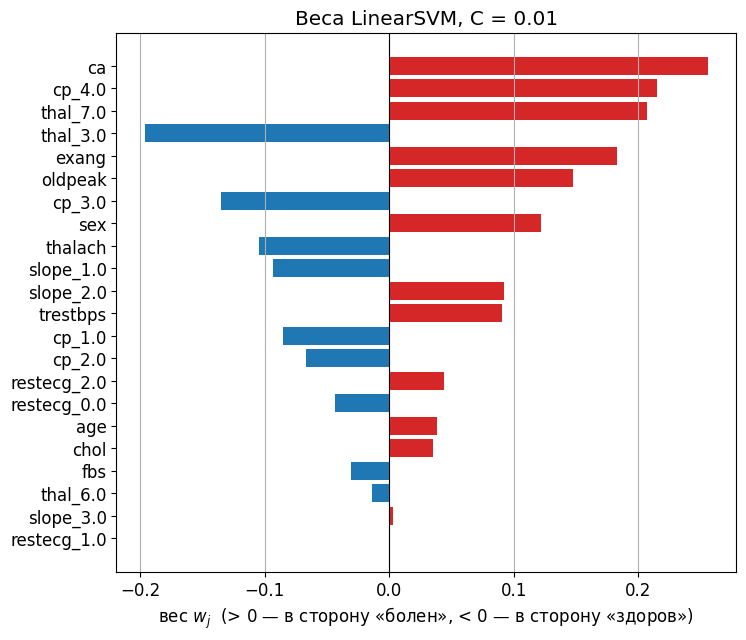

,признак,w,|w|
0,ca,0.256,0.256
1,cp_4.0,0.215,0.215
2,thal_7.0,0.207,0.207
3,thal_3.0,-0.197,0.197
4,exang,0.183,0.183
5,oldpeak,0.148,0.148
6,cp_3.0,-0.135,0.135
7,sex,0.122,0.122
8,thalach,-0.105,0.105
9,slope_1.0,-0.093,0.093


In [47]:
imp = pd.DataFrame({'признак': feature_names, 'w': lin_best.weights_, '|w|': np.abs(lin_best.weights_)})
imp = imp.sort_values('|w|', ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 7))
colors = np.where(imp['w'] > 0, 'tab:red', 'tab:blue')
plt.barh(imp['признак'][::-1], imp['w'][::-1], color=colors[::-1])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('вес $w_j$  (> 0 — в сторону «болен», < 0 — в сторону «здоров»)')
plt.title(f'Веса LinearSVM, C = {best_C_lin:g}')
plt.grid(True, axis='x')
plt.show()
imp.round(3)

**Важность признаков и клиническая интерпретация.** Знак веса показывает направление: $w_j > 0$ сдвигает прогноз к «болен».

1. **`ca` (0.26)** — число крупных сосудов, окрашенных при флуороскопии (ангиография). Это прямое изображение коронарных артерий, почти «золотой стандарт» диагностики, поэтому неудивительно, что признак на первом месте.
2. **`cp_4.0` (+0.22)** — тип боли «бессимптомный». Парадокс только кажущийся. В клинику Кливленда направляли пациентов с подозрением на ИБС, и если у человека без типичной боли назначили коронарографию, значит, на болезнь указывали другие данные. Это хорошо известная особенность датасета. «Нетипичная» и «неангинозная» боль (`cp_2`, `cp_3`) и даже типичная стенокардия (`cp_1`) входят с отрицательными весами, относительно `cp_4`.
3. **`thal_7.0` (+0.21) / `thal_3.0` (−0.20)** — сцинтиграфия миокарда. Обратимый дефект перфузии означает ишемию при нагрузке, норма — здоровое сердце.
4. **`exang` (+0.18), `oldpeak` (+0.15), `slope`** — нагрузочный ЭКГ-тест: стенокардия при нагрузке, депрессия ST, плоский (`slope_2`, +) против восходящего (`slope_1`, −) сегмента ST. Это классические критерии ишемии.
5. **`sex` (+0.12)**: мужской пол — известный фактор риска ИБС. **`thalach` (−0.11)**: высокий достижимый пульс говорит о хорошей переносимости нагрузки.
6. **`age` (0.04) и `chol` (0.035)** — в самом конце списка, рядом с `fbs`.

**Согласуется ли с медицинской интуицией?** Да. **Боль в груди** (тип `cp`) на втором месте, а **возраст и холестерин** почти не важны. Модель опирается на **результаты диагностических обследований** (ангиография, сцинтиграфия, нагрузочная ЭКГ): они измеряют саму болезнь. Классические **факторы риска** (возраст, холестерин, сахар, давление) лишь повышают её вероятность в популяции. Кроме того, веса линейной модели показывают вклад признака *при прочих равных*. Возраст коррелирует с `ca` и `thalach` (у пожилых чаще поражены сосуды и ниже максимальный пульс), и его информация уже «забрана» этими признаками. Поэтому малый вес `age` не значит, что возраст не связан с болезнью. Это не причинно-следственный анализ: модуль веса — мера полезности признака *для этой модели* на этих данных.

**Доля опорных векторов в зависимости от $C$:**

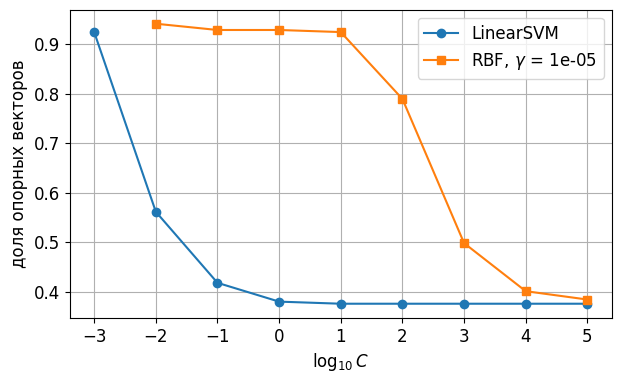

,C,SV,доля SV,внутри коридора |f|<1,ошибки на train
0,0.001,219,0.924,217,42
1,0.010,133,0.561,120,36
2,0.100,99,0.418,82,33
3,1.000,90,0.380,67,30
4,10.000,89,0.376,62,30
5,100.000,89,0.376,63,30
6,1000.000,89,0.376,64,30
7,10000.000,89,0.376,63,30
8,100000.000,89,0.376,64,30


In [48]:
sv_rows = []
for C in C_lin:
    m = LinearSVM(C=C).fit(X_train, y_train)
    on_border = np.sum(np.abs(y_train * m.decision_function(X_train)) < 1)   # внутри коридора |f(x)| < 1
    sv_rows.append({'C': C, 'SV': len(m.support_), 'доля SV': len(m.support_) / len(y_train),
                    'внутри коридора |f|<1': on_border,
                    'ошибки на train': np.sum(m.predict(X_train) != y_train)})
sv_df = pd.DataFrame(sv_rows)

plt.figure(figsize=(7, 4))
plt.plot(np.log10(sv_df['C']), sv_df['доля SV'], 'o-', label='LinearSVM')
plt.plot(np.log10(C_hd), [len(DualSVM(C=C, kernel=partial(rbf_kernel, gamma=best_g_rbf)).fit(X_train, y_train).support_) / len(y_train)
                          for C in C_hd], 's-', label=f'RBF, $\\gamma$ = {best_g_rbf:g}')
plt.xlabel('$\\log_{10} C$'); plt.ylabel('доля опорных векторов'); plt.grid(True); plt.legend()
plt.show()
sv_df.round(3)

**Доля опорных векторов.**

- У линейного SVM доля SV падает с **92%** при $C = 10^{-3}$ до **56%** при $C = 10^{-2}$ (выбранная модель), **42%** при $C = 0.1$ и выходит на плато **38%** (89 из 237) при $C \ge 1$. Механизм тот же, что в задании 2: маленькое $C$ даёт широкий коридор, в который попадают почти все. У RBF-модели та же тенденция.
- **Много ли пациентов «на границе»?** Да, и это главный содержательный вывод. Даже при максимальном $C$ опорными остаются 38% пациентов: из них **30** классифицируются неверно, а ещё около 60 лежат внутри коридора $\lvert f(\boldsymbol x)\rvert < 1$ (26% выборки). В выбранной модели с $C = 0.01$ внутри коридора половина пациентов (120 из 237). По имеющимся 13 показателям значительная часть пациентов неоднозначна: их обследование «похоже» и на здоровых, и на больных. Отсюда и «потолок» качества около 83–87% у всех моделей, линейных и нелинейных.

**Практический вывод:** такой классификатор годится как **скрининговая поддержка решения** врача. Пациенты далеко от границы ($\lvert f \rvert \gg 1$) классифицируются уверенно. Пациентов внутри коридора разумно направлять на дополнительное обследование, а не полагаться на прогноз модели.

## Итог: что должно быть в отчёте

- **Задание 1** — задачи LP и QP: план производства с картинкой и перебором вершин, тестовая QP-задача, анализ активных ограничений, сравнение LP и QP.
- **Задание 2** — три выборки, эксперименты линейного SVM с разными $C$, квадратичная граница через явное преобразование признаков.
- **Задание 3** — эксперименты ядрового SVM (линейное, полиномиальное, RBF-ядро) с выводами о влиянии $C$, $p$, $\gamma$.
- **Задание 4** — разведка и подготовка данных о болезнях сердца с пояснениями, подбор гиперпараметров своего SVM, сравнение с `sklearn.svm.SVC`, ответы на вопросы.

Код сам по себе не оценивается — оцениваются полнота ответов, корректность экспериментов и аргументированность выводов.